# StageOps — Punto 1: Localizar las incidencias

> *"01. Localizar las incidencias. Identifiquen los conciertos, proveedores y periodos con problemas demostrables. Comparen con operaciones correctas para comprobar si el comportamiento es general o está acotado."*

**Nota:** las variables de este punto y del Punto 5 llevan el prefijo `p1_` y `p5_`, para no pisar las de los puntos 3 y 4.

---

## 1. Carga de los 6 CSV y conversión de fechas

**¿Por qué hacemos este paso?** Las fechas llegan como texto y no se pueden comparar. Se pasan todas a UTC con `to_datetime`.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Carpeta de los CSV: /content en Colab o la carpeta actual
P1_DIR = next((d for d in ["/content", ".", "datos", "StageOps_Material"]
               if os.path.exists(os.path.join(d, "reservations.csv"))), ".")

def p1_leer(nombre):
    return pd.read_csv(os.path.join(P1_DIR, nombre), encoding="utf-8-sig")

p1_concerts = p1_leer("concerts.csv")
p1_reservations = p1_leer("reservations.csv")
p1_payments = p1_leer("payment_events.csv")
p1_tickets = p1_leer("tickets.csv")
p1_changes = p1_leer("system_changes.csv")

# Texto -> fecha (UTC)
for col in ["created_at", "expires_at"]:
    p1_reservations[col] = pd.to_datetime(p1_reservations[col], utc=True)
for col in ["occurred_at", "received_at"]:
    p1_payments[col] = pd.to_datetime(p1_payments[col], utc=True)
for col in ["issued_at", "voided_at"]:
    p1_tickets[col] = pd.to_datetime(p1_tickets[col], utc=True)
p1_changes["effective_at"] = pd.to_datetime(p1_changes["effective_at"], utc=True)
p1_snapshot = pd.to_datetime(p1_concerts["snapshot_at"], utc=True).max()   # cierre de los datos

P1_VERDE, P1_ROJO, P1_GRIS = "#55A868", "#C44E52", "#B0B7C3"
print("Datos cargados desde", P1_DIR)

Datos cargados desde StageOps_Material


## 2. Historial de cambios: la pista

**¿Por qué hacemos este paso?** Si algo empezó a fallar, lo primero es mirar qué se cambió. Solo **CHG-004** (EntradaLink, 16/10 a las 10:20Z, `ticket_issuer` 4.8.0) toca la regla que decide si se emite una entrada: pasa de `CURRENT_OWNER_AND_NOT_EXPIRED` a `PAYMENT_REFERENCE_EXISTS`. De momento es una sospecha; se comprueba con los datos en los pasos siguientes.

In [2]:
p1_changes.sort_values("effective_at")[["change_id", "ticketing_company_id", "effective_at", "component",
                                        "version", "setting_name", "old_value", "new_value"]]

,change_id,ticketing_company_id,effective_at,component,version,setting_name,old_value,new_value
1,CHG-001,LT,2026-09-28 06:00:00+00:00,ticket_issuer,7.3.1,reservation_validation,NaN,CURRENT_OWNER_AND_NOT_EXPIRED
5,CHG-002,EL,2026-09-28 06:00:00+00:00,ticket_issuer,4.7.2,reservation_validation,NaN,CURRENT_OWNER_AND_NOT_EXPIRED
3,CHG-003,LT,2026-10-14 05:00:00+00:00,web,7.3.2,cache_ttl_seconds,60,45
0,CHG-004,EL,2026-10-16 10:20:00+00:00,ticket_issuer,4.8.0,reservation_validation,CURRENT_OWNER_AND_NOT_EXPIRED,PAYMENT_REFERENCE_EXISTS
2,CHG-005,LT,2026-10-20 06:00:00+00:00,payments,7.3.1,callback_retry_seconds,30,20
4,CHG-006,EL,2026-10-22 05:30:00+00:00,web,4.8.1,cache_ttl_seconds,60,45


## 3. Tabla de operaciones: un cobro por fila, sin reenvíos

**¿Por qué hacemos este paso?** Se quitan los reenvíos de webhook, que tienen el mismo `provider_event_id` (igual que en el Punto 4). Después se une cada cobro con su reserva, su concierto y su entrada, si la tiene. Un aviso es **tardío** si `received_at >= expires_at`, es decir, si llega cuando la reserva ya ha caducado.

In [3]:
# Quitar reenvíos: se queda la primera llegada de cada provider_event_id
p1_pagos = p1_payments.sort_values("received_at").drop_duplicates("provider_event_id")
p1_capturas = p1_pagos[p1_pagos["event_type"] == "CAPTURED"]
p1_devoluciones = p1_pagos[p1_pagos["event_type"] == "REFUNDED"]

# Cobro + reserva + concierto + entrada
p1_ops = p1_capturas[["reservation_id", "payment_id", "amount_eur", "occurred_at", "received_at"]].merge(
    p1_reservations, on="reservation_id")
p1_ops = p1_ops.merge(p1_concerts[["concert_id", "ticketing_company_id"]], on="concert_id")
p1_ops = p1_ops.merge(p1_tickets[["reservation_id", "ticket_id", "issued_at", "voided_at", "issuer_version"]],
                      on="reservation_id", how="left")

p1_ops["con_entrada"] = p1_ops["ticket_id"].notna()
p1_ops["devuelto"] = p1_ops["reservation_id"].isin(p1_devoluciones["reservation_id"])
p1_ops["tardia"] = p1_ops["received_at"] >= p1_ops["expires_at"]          # aviso con la reserva caducada
p1_ops["dia"] = p1_ops["created_at"].dt.tz_convert("Europe/Madrid").dt.date

print("Cobros únicos:", len(p1_ops), "| avisos tardíos:", p1_ops["tardia"].sum())

Cobros únicos: 178043 | avisos tardíos: 3669


## 4. Comprobación del dinero: las devoluciones no se cuentan como incidencia

**¿Por qué hacemos este paso?** Se cruzan todos los cobros según tres preguntas: ¿llegó tarde?, ¿tiene entrada?, ¿se devolvió? Así se ve que las 5.046 devoluciones son **3.565 anulaciones legítimas + 1.481 avisos tardíos bien resueltos**, y que solo queda una casilla incorrecta.

In [4]:
pd.crosstab([p1_ops["tardia"].map({False: "a tiempo", True: "tarde"}),
             p1_ops["con_entrada"].map({False: "sin entrada", True: "con entrada"}),
             p1_ops["voided_at"].notna().map({False: "", True: "anulada después"})],
            p1_ops["devuelto"].map({False: "no devuelto", True: "devuelto"}))

devuelto                              devuelto  no devuelto
tardia   con_entrada voided_at                             
a tiempo con entrada                         0       170809
                     anulada después      3565            0
tarde    con entrada                         0         2188
         sin entrada                      1481            0

## 5. ¿Qué se hizo con los avisos tardíos? (el hallazgo)

**¿Por qué hacemos este paso?** La regla dice que un aviso tardío debe acabar en **devolución sin entrada**. Se clasifican las 4 combinaciones posibles sin dar ninguna por supuesta.

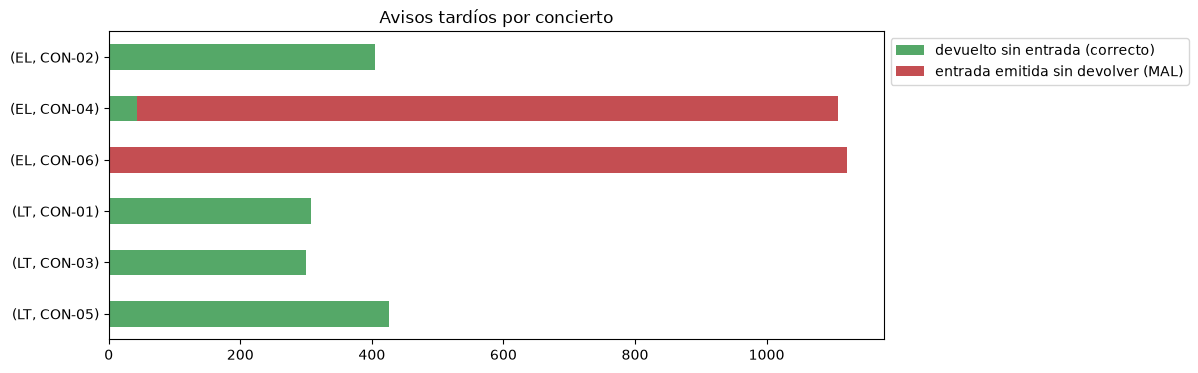

resultado                        devuelto sin entrada (correcto)  \
ticketing_company_id concert_id                                    
EL                   CON-02                                  405   
                     CON-04                                   43   
                     CON-06                                    0   
LT                   CON-01                                  307   
                     CON-03                                  300   
                     CON-05                                  426   

resultado                        entrada emitida sin devolver (MAL)  
ticketing_company_id concert_id                                      
EL                   CON-02                                       0  
                     CON-04                                    1066  
                     CON-06                                    1122  
LT                   CON-01                                       0  
                     CON-03                                       0  
                     CON-05                                       0

In [5]:
p1_tardias = p1_ops[p1_ops["tardia"]].copy()
p1_tardias["resultado"] = "otro caso (revisar)"
p1_tardias.loc[~p1_tardias["con_entrada"] & p1_tardias["devuelto"], "resultado"] = "devuelto sin entrada (correcto)"
p1_tardias.loc[p1_tardias["con_entrada"] & ~p1_tardias["devuelto"], "resultado"] = "entrada emitida sin devolver (MAL)"
p1_indebidas = p1_tardias[p1_tardias["resultado"] == "entrada emitida sin devolver (MAL)"]

p1_tabla = pd.crosstab([p1_tardias["ticketing_company_id"], p1_tardias["concert_id"]], p1_tardias["resultado"])
p1_tabla.plot.barh(stacked=True, color=[P1_VERDE, P1_ROJO], figsize=(10, 4), title="Avisos tardíos por concierto")
plt.gca().invert_yaxis(); plt.ylabel(""); plt.legend(loc="upper left", bbox_to_anchor=(1, 1)); plt.show()
p1_tabla

## 6. Versión del emisor y grupo de control

**¿Por qué hacemos este paso?** Hay que comprobar dos cosas: qué versión emitió las entradas incorrectas, y si la misma situación (aviso tardío) se resolvía bien antes del cambio y en la otra compañía. Esto acota el fallo.

In [6]:
# Versión del emisor de las entradas incorrectas
display(pd.crosstab(p1_indebidas["concert_id"], p1_indebidas["issuer_version"], margins=True, margins_name="Total"))

# Grupo de control: compañía x antes/después de CHG-004
p1_cambio = p1_changes.loc[p1_changes["change_id"] == "CHG-004", "effective_at"].iloc[0]
p1_tardias["momento"] = p1_tardias["received_at"].ge(p1_cambio).map({False: "antes CHG-004", True: "después CHG-004"})
pd.crosstab([p1_tardias["ticketing_company_id"], p1_tardias["momento"]], p1_tardias["resultado"])

issuer_version,4.8.0,Total
concert_id,,
CON-04,1066,1066
CON-06,1122,1122
Total,2188,2188


resultado                             devuelto sin entrada (correcto)  \
ticketing_company_id momento                                            
EL                   antes CHG-004                                448   
                     después CHG-004                                0   
LT                   antes CHG-004                                338   
                     después CHG-004                              695   

resultado                             entrada emitida sin devolver (MAL)  
ticketing_company_id momento                                              
EL                   antes CHG-004                                     0  
                     después CHG-004                                2188  
LT                   antes CHG-004                                     0  
                     después CHG-004                                   0

## 7. Periodo y volumen: ¿por qué solo el 16/10 y el 23/10?

**¿Por qué hacemos este paso?** La versión 4.8.0 está activa desde el 16/10, pero las entradas incorrectas solo aparecen dos días. Se compara el volumen de cada día: compras, compras en el minuto de más actividad, espera máxima del aviso de pago y avisos tardíos.

In [7]:
# Primera y última incidencia (hora de España)
p1_periodo = p1_indebidas.groupby("concert_id")["received_at"].agg(casos="count", primera="min", ultima="max")
for col in ["primera", "ultima"]:
    p1_periodo[col] = p1_periodo[col].dt.tz_convert("Europe/Madrid").dt.strftime("%d/%m %H:%M")
display(p1_periodo)

# Volumen por día
p1_ops["espera_min"] = (p1_ops["received_at"] - p1_ops["occurred_at"]).dt.total_seconds() / 60
p1_ops["minuto"] = p1_ops["created_at"].dt.floor("min")
p1_pico = p1_ops.groupby(["concert_id", "dia", "minuto"]).size().groupby(["concert_id", "dia"]).max()

p1_volumen = p1_ops.groupby(["ticketing_company_id", "concert_id", "dia"]).agg(
    compras=("reservation_id", "size"),
    avisos_tarde=("tardia", "sum"),
    entradas_incorrectas=("reservation_id", lambda s: s.isin(p1_indebidas["reservation_id"]).sum()),
    espera_max_min=("espera_min", "max"))
p1_volumen = p1_volumen.join(p1_pico.rename("compras_minuto_pico"), on=["concert_id", "dia"])
p1_volumen.round(1)

,casos,primera,ultima
concert_id,,,
CON-04,1066,16/10 12:20,16/10 20:14
CON-06,1122,23/10 12:12,23/10 20:17


compras  avisos_tarde  \
ticketing_company_id concert_id dia                                 
EL                   CON-02     2026-10-03    30174           405   
                                2026-10-04      114             0   
                                2026-10-05      297             0   
                                2026-10-06      195             0   
                     CON-04     2026-10-16    31446          1109   
                                2026-10-17      120             0   
                                2026-10-18      316             0   
                                2026-10-19      216             0   
                     CON-06     2026-10-23    27958          1122   
                                2026-10-24      131             0   
                                2026-10-25      261             0   
                                2026-10-26      182             0   
LT                   CON-01     2026-10-02    26898           307   
                                2026-10-03      102             0   
                                2026-10-04      273             0   
                                2026-10-05      142             0   
                     CON-03     2026-10-16    25211           300   
                                2026-10-17      106             0   
                                2026-10-18      288             0   
                                2026-10-19      129             0   
                     CON-05     2026-10-23    32791           426   
                                2026-10-24      129             0   
                                2026-10-25      350             0   
                                2026-10-26      214             0   

                                            entradas_incorrectas  \
ticketing_company_id concert_id dia                                
EL                   CON-02     2026-10-03                     0   
                                2026-10-04                     0   
                                2026-10-05                     0   
                                2026-10-06                     0   
                     CON-04     2026-10-16                  1066   
                                2026-10-17                     0   
                                2026-10-18                     0   
                                2026-10-19                     0   
                     CON-06     2026-10-23                  1122   
                                2026-10-24                     0   
                                2026-10-25                     0   
                                2026-10-26                     0   
LT                   CON-01     2026-10-02                     0   
                                2026-10-03                     0   
                                2026-10-04                     0   
                                2026-10-05                     0   
                     CON-03     2026-10-16                     0   
                                2026-10-17                     0   
                                2026-10-18                     0   
                                2026-10-19                     0   
                     CON-05     2026-10-23                     0   
                                2026-10-24                     0   
                                2026-10-25                     0   
                                2026-10-26                     0   

                                            espera_max_min  \
ticketing_company_id concert_id dia                          
EL                   CON-02     2026-10-03            17.2   
                                2026-10-04             5.8   
                                2026-10-05             5.8   
                                2026-10-06             5.8   
                     CON-04     2026-10-16            17.6   
                                2026-10-17    

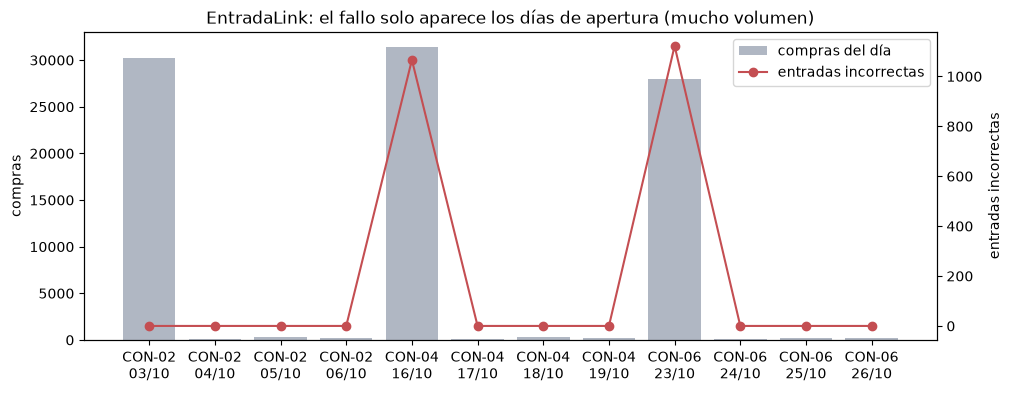

In [8]:
# Gráfico: compras del día (barras) y entradas incorrectas (línea) en EntradaLink
p1_el = p1_volumen.loc["EL"].reset_index()
p1_el["etiqueta"] = p1_el["concert_id"] + "\n" + pd.to_datetime(p1_el["dia"]).dt.strftime("%d/%m")
fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.bar(p1_el["etiqueta"], p1_el["compras"], color=P1_GRIS, label="compras del día")
ax1.set_ylabel("compras")
ax2 = ax1.twinx()
ax2.plot(p1_el["etiqueta"], p1_el["entradas_incorrectas"], "o-", color=P1_ROJO, label="entradas incorrectas")
ax2.set_ylabel("entradas incorrectas")
ax1.set_title("EntradaLink: el fallo solo aparece los días de apertura (mucho volumen)")
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.88)); plt.show()

## 8. Cifras del Punto 1

**¿Por qué hacemos este paso?** Las cifras de la conclusión se imprimen desde el código, para que no haya números escritos a mano.

In [9]:
# Butacas con dos entradas vigentes a la vez
p1_ent = p1_tickets.copy()
p1_ent["fin"] = p1_ent["voided_at"].fillna(p1_snapshot)
p1_ent = p1_ent.sort_values(["concert_id", "seat_id", "issued_at"])
p1_ent["fin_anterior"] = p1_ent.groupby(["concert_id", "seat_id"])["fin"].shift()
p1_dobles = p1_ent[p1_ent["issued_at"] < p1_ent["fin_anterior"]][["concert_id", "seat_id"]].drop_duplicates()

print("Entradas emitidas con la reserva caducada:", len(p1_indebidas),
      "| todas versión 4.8.0:", (p1_indebidas["issuer_version"] == "4.8.0").all())
print("  de ellas, en butacas con dos entradas a la vez:", len(p1_dobles))
print("  sin choque con otra entrada:", len(p1_indebidas) - len(p1_dobles))
print("Importe cobrado de esas entradas:", p1_indebidas["amount_eur"].sum(), "€")
print("Avisos tardíos bien resueltos (devolución sin entrada):",
      (p1_tardias["resultado"] == "devuelto sin entrada (correcto)").sum())

Entradas emitidas con la reserva caducada: 2188 | todas versión 4.8.0: True
  de ellas, en butacas con dos entradas a la vez: 1195
  sin choque con otra entrada: 993
Importe cobrado de esas entradas: 187738.0 €
Avisos tardíos bien resueltos (devolución sin entrada): 1481


---
## 📝 9. Conclusiones Redactadas del Punto 1 (Listas para el Informe)

**Dónde.** Las incidencias se limitan a **EntradaLink** y a dos conciertos: **CON-04** (Mar Abierto, Valencia) y **CON-06** (Los Días Azules, A Coruña). Hay **2.188 entradas** emitidas a partir de reservas que ya habían caducado cuando llegó el aviso de pago: 1.066 en CON-04 y 1.122 en CON-06. Según la regla del servicio, en esos casos había que devolver el dinero sin emitir entrada. En **1.195 butacas** esa entrada convive con la de otro comprador que reservó correctamente después; las otras 993 no chocan con nadie, pero tampoco debían emitirse. Los cobros afectados suman **187.738 €**.

**Qué cambió.** El 16/10 a las 10:20Z (12:20 en España), EntradaLink instaló la versión **4.8.0** de su emisor de entradas (**CHG-004**). Esa versión dejó de comprobar que la reserva siguiera vigente y siguiera siendo del comprador (`CURRENT_OWNER_AND_NOT_EXPIRED`). Desde entonces solo comprueba que exista un pago (`PAYMENT_REFERENCE_EXISTS`). Las 2.188 entradas incorrectas son todas de la versión 4.8.0: la última entrada de la versión anterior (4.7.2) sale a las 10:20:01Z y la primera de la 4.8.0 a las 10:20:02Z.

**Comparación con las operaciones correctas.** Con avisos tardíos, LumaTicket (CON-01, CON-03 y CON-05) devolvió el dinero en todos sus casos (1.033), y EntradaLink también lo hacía antes del cambio (448). CON-02 está limpio porque toda su venta fue anterior a la actualización. Los cambios de caché web y de reintentos no encajan: LumaTicket también los tuvo y no tiene casos, y el cambio de caché de EntradaLink es del 22/10, cuando el fallo ya había empezado. El comportamiento no es general: **está acotado a EntradaLink después de CHG-004**.

**Por qué solo el 16/10 y el 23/10: el volumen.** El fallo existe desde la actualización, pero solo se activa cuando un aviso de pago llega con la reserva ya caducada, y eso solo ocurre con mucho volumen. Los días de apertura de venta concentran casi toda la demanda:

| EntradaLink | Día de apertura (16/10 y 23/10) | Resto de días |
|---|---|---|
| Compras por día | 27.958 – 31.446 | 114 – 316 |
| Compras en el minuto de más actividad | 1.116 – 1.309 | 2 – 4 |
| Espera máxima del aviso de pago | 17,6 – 17,7 minutos | menos de 6 minutos |
| Avisos tardíos | 1.109 y 1.122 | 0 |

Con esa saturación, los avisos del banco tardan más de lo que le queda a la reserva. CON-04 abrió el 16/10 a las 12:00 y la actualización llegó 20 minutos después, en plena apertura. CON-06 abrió el 23/10 con la 4.8.0 ya instalada. Los días siguientes ningún aviso llegó tarde y no hubo entradas incorrectas, aunque la versión defectuosa seguía activa.

**Periodo (hora de España).** CON-04: el 16/10, de 12:20 a 20:14. CON-06: el 23/10, de 12:12 a 20:17.

**Qué está demostrado y qué no.** Está demostrado que las entradas incorrectas solo salen de la versión 4.8.0 de EntradaLink y que, ante avisos tardíos, el resto de casos se resolvió bien. Para atribuir la causa con total seguridad al cambio de la regla harían falta los registros o el código del emisor de EntradaLink: una fecha próxima, por sí sola, no lo prueba. Como la 4.8.0 sigue activa al cierre de los datos (28/10), **el fallo se repetirá en la próxima apertura de ventas de EntradaLink** si no se corrige.

# Problema 2: ¿Qué operaciones repetidas son normales y cuáles son errores reales?
**Objetivo:** Revisar todas las tablas para separar las **repeticiones normales del negocio** (falsas alarmas) de los **errores reales del sistema** (incidencias que afectan a clientes y dinero).

In [10]:
import os
import pandas as pd

# Mostrar todo el texto completo en las tablas sin cortarlo con '...'
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 1000)

# Detecta automáticamente la ruta tanto en local (VS Code) como en Google Colab
P2_DIR = next((d for d in ["/content", ".", "datos", "StageOps_Material"]
               if os.path.exists(os.path.join(d, "reservations.csv"))), ".")

customers_p2 = pd.read_csv(os.path.join(P2_DIR, "customers.csv"), encoding="utf-8-sig")
reservations_p2 = pd.read_csv(os.path.join(P2_DIR, "reservations.csv"), encoding="utf-8-sig")
payments_p2 = pd.read_csv(os.path.join(P2_DIR, "payment_events.csv"), encoding="utf-8-sig")
tickets_p2 = pd.read_csv(os.path.join(P2_DIR, "tickets.csv"), encoding="utf-8-sig")
print("Archivos cargados correctamente desde", P2_DIR)

Archivos cargados correctamente desde StageOps_Material


## Parte A: Repeticiones que parecen errores pero son LEGÍTIMAS (Falsas alarmas)
Explicación en lenguaje de negocio para dirección de por qué estos registros repetidos son situaciones normales y correctas.

In [11]:
# A1. Mismo código de butaca en conciertos distintos
seat_concerts = reservations_p2.groupby("seat_id")["concert_id"].nunique()
seats_multi_concert = int((seat_concerts > 1).sum())

# A2. Clientes que se llaman igual (homónimos)
counts_nombre = customers_p2.groupby(["first_name", "last_name"])["customer_id"].count()
clientes_homonimos = int(counts_nombre[counts_nombre > 1].sum())

# A3. Compras en grupo (un pedido con varias butacas) o clientes que compran varias veces
pedidos_multi_reserva = int((reservations_p2.groupby("order_id").size() > 1).sum())
clientes_multi_reserva = int((reservations_p2.groupby("customer_id").size() > 1).sum())

# A4. Mensajes de pago repetidos por lentitud de conexión (reenvíos del banco)
reenvios_pasarela = int((payments_p2["delivery_attempt"] > 1).sum())

# Quitamos esos mensajes repetidos para analizar los cobros y devoluciones reales
pay_unicos = payments_p2.drop_duplicates(subset=["provider_event_id"]).copy()
tiene_captured = set(pay_unicos[pay_unicos["event_type"] == "CAPTURED"]["reservation_id"])
tiene_refunded = set(pay_unicos[pay_unicos["event_type"] == "REFUNDED"]["reservation_id"])

# A5. Reservas con 2 apuntes bancarios (Cobro + Devolución) porque el pago llegó tarde
res_con_ticket = set(tickets_p2["reservation_id"])
pagos_tardios_reembolsados = len((tiene_captured & tiene_refunded) - res_con_ticket)
total_captura_mas_reembolso = len(tiene_captured & tiene_refunded)

# Cruce de reservas y entradas por asiento
res_tkt = reservations_p2.merge(
    tickets_p2[["reservation_id", "ticket_id", "issued_at", "voided_at", "issuer_version"]],
    on="reservation_id",
    how="left"
)
res_tkt["es_tardia"] = res_tkt["issued_at"].notna() & (res_tkt["issued_at"] >= res_tkt["expires_at"])
res_tkt["tkt_vigente"] = res_tkt["ticket_id"].notna() & res_tkt["voided_at"].isna()
res_tkt["tkt_anulado"] = res_tkt["ticket_id"].notna() & res_tkt["voided_at"].notna()

butacas_grp = res_tkt.groupby(["concert_id", "seat_id"]).agg(
    n_reservas=("reservation_id", "count"),
    n_tickets_emitidos=("ticket_id", lambda s: s.notna().sum()),
    n_tickets_vigentes=("tkt_vigente", "sum"),
    n_tickets_anulados=("tkt_anulado", "sum"),
    n_emisiones_tardias=("es_tardia", "sum")
).reset_index()

# A6. Asientos reservados 2 veces porque el primer cliente abandonó el carrito a los 10 min
reintento_reserva_caducada = int(
    ((butacas_grp["n_reservas"] == 2) &
     (butacas_grp["n_tickets_emitidos"] == 1) &
     (butacas_grp["n_emisiones_tardias"] == 0)).sum()
)

# A7. Asientos con 2 entradas donde el primer comprador canceló su entrada antes de revenderse
reventa_tras_anulacion = int(
    ((butacas_grp["n_tickets_emitidos"] == 2) &
     (butacas_grp["n_tickets_anulados"] == 1) &
     (butacas_grp["n_tickets_vigentes"] == 1)).sum()
)

tabla_legitimas = pd.DataFrame([
    [
        "1. Mismo número de asiento en varios conciertos",
        seats_multi_concert,
        "códigos de asiento",
        "Es normal que el 'Sector 1, Fila 1, Butaca 1' exista en el concierto de Madrid y también en el de Sevilla. Como son eventos distintos, no chocan."
    ],
    [
        "2. Clientes con el mismo nombre y apellido",
        clientes_homonimos,
        "clientes distintos",
        "No son fichas duplicadas: son personas reales que se llaman igual (ej. dos 'Carla Ramos'), pero cada una tiene su propio código de cliente y su propio email."
    ],
    [
        "3. Un mismo pedido o cliente con varias reservas",
        pedidos_multi_reserva,
        "pedidos grupales",
        f"Una persona puede comprar entradas para sus acompañantes en un mismo pedido (hay {clientes_multi_reserva} compradores que reservaron más de un asiento)."
    ],
    [
        "4. Avisos de cobro repetidos por la pasarela bancaria",
        reenvios_pasarela,
        "mensajes duplicados",
        "El banco cobró una sola vez al cliente, pero al tardar en recibir confirmación informática envió el mismo aviso 2 o 3 veces. No es un cobro doble."
    ],
    [
        "5. Reservas con 2 movimientos bancarios (Cobro + Reembolso)",
        pagos_tardios_reembolsados,
        "reservas reembolsadas",
        "El aviso del pago llegó cuando los 10 minutos de reserva ya habían expirado. El sistema actuó bien: no dio entrada y devolvió el dinero automáticamente."
    ],
    [
        "6. Asiento reservado 2 veces (carrito abandonado)",
        reintento_reserva_caducada,
        "butacas",
        "Un primer interesado bloqueó el asiento pero no pagó en los 10 minutos. El asiento volvió a quedar libre legalmente y otro cliente lo compró después."
    ],
    [
        "7. Asiento con 2 entradas (la 1ª fue cancelada antes)",
        reventa_tras_anulacion,
        "butacas",
        "El primer comprador adquirió su entrada, pero luego la anuló y se le devolvió el dinero. Al quedar libre el asiento, se vendió legalmente a otra persona."
    ]
], columns=["Qué parece repetido en los archivos (LEGÍTIMO)", "Cantidad", "Unidad", "Explicación sencilla para Dirección (Por qué es correcto)"])

tabla_legitimas

,Qué parece repetido en los archivos (LEGÍTIMO),Cantidad,Unidad,Explicación sencilla para Dirección (Por qué es correcto)
0,1. Mismo número de asiento en varios conciertos,31955,códigos de asiento,"Es normal que el 'Sector 1, Fila 1, Butaca 1' exista en el concierto de Madrid y también en el de Sevilla. Como son eventos distintos, no chocan."
1,2. Clientes con el mismo nombre y apellido,41198,clientes distintos,"No son fichas duplicadas: son personas reales que se llaman igual (ej. dos 'Carla Ramos'), pero cada una tiene su propio código de cliente y su propio email."
2,3. Un mismo pedido o cliente con varias reservas,61168,pedidos grupales,Una persona puede comprar entradas para sus acompañantes en un mismo pedido (hay 47828 compradores que reservaron más de un asiento).
3,4. Avisos de cobro repetidos por la pasarela bancaria,4463,mensajes duplicados,"El banco cobró una sola vez al cliente, pero al tardar en recibir confirmación informática envió el mismo aviso 2 o 3 veces. No es un cobro doble."
4,5. Reservas con 2 movimientos bancarios (Cobro + Reembolso),1481,reservas reembolsadas,El aviso del pago llegó cuando los 10 minutos de reserva ya habían expirado. El sistema actuó bien: no dio entrada y devolvió el dinero automáticamente.
5,6. Asiento reservado 2 veces (carrito abandonado),4547,butacas,Un primer interesado bloqueó el asiento pero no pagó en los 10 minutos. El asiento volvió a quedar libre legalmente y otro cliente lo compró después.
6,7. Asiento con 2 entradas (la 1ª fue cancelada antes),3565,butacas,"El primer comprador adquirió su entrada, pero luego la anuló y se le devolvió el dinero. Al quedar libre el asiento, se vendió legalmente a otra persona."


## Parte B: Operaciones que generan un CONFLICTO REAL (Incidencias graves)
Explicación en lenguaje claro de qué ha fallado realmente en la empresa **EntradaLink** a partir de su actualización del 16 de octubre.

In [12]:
# B1. Doble venta del mismo asiento (Overbooking: 2 personas con entrada válida a la vez)
butacas_doble_vigente = int((butacas_grp["n_tickets_vigentes"] == 2).sum())
tickets_en_doble_vigente = butacas_doble_vigente * 2

# B2. Entrada entregada fuera de tiempo (aunque nadie más compró ese asiento)
butacas_tardia_unica = int(
    ((butacas_grp["n_tickets_vigentes"] == 1) &
     (butacas_grp["n_emisiones_tardias"] == 1)).sum()
)

# Total de entradas emitidas incumpliendo la regla de los 10 minutos
total_emisiones_caducadas = int(res_tkt["es_tardia"].sum())

tabla_conflictos = pd.DataFrame([
    [
        "1A. Doble venta del mismo asiento (Overbooking / 2 entradas activas)",
        butacas_doble_vigente,
        "butacas con 2 dueños",
        f"El Cliente 1 tardó más de 10 min en confirmar su pago y perdió la reserva. El Cliente 2 compró ese asiento legalmente. Cuando por fin llegó el pago atrasado del Cliente 1, el sistema falló y le dio entrada igual. Hay {tickets_en_doble_vigente} entradas válidas para {butacas_doble_vigente} asientos."
    ],
    [
        "1B. Entrada emitida con la reserva ya caducada (sin 2º comprador)",
        butacas_tardia_unica,
        "butacas / entradas",
        "El aviso de pago llegó pasados los 10 minutos límite. Como nadie más había comprado ese asiento todavía, no hay dos personas para la misma silla, pero el sistema incumplió la norma: debía haber rechazado la compra y devuelto el dinero en vez de dar la entrada."
    ],
    [
        "TOTAL DE ENTRADAS EMITIDAS ILEGALMENTE FUERA DE PLAZO (1A + 1B)",
        total_emisiones_caducadas,
        "entradas irregulares",
        "Todas ocurren en la proveedora EntradaLink tras su cambio informático del 16 de octubre (versión 4.8.0), donde desactivaron la comprobación de si la reserva había caducado."
    ]
], columns=["Conflicto Real Detectado (INCIDENCIA)", "Cantidad", "Unidad", "Explicación sencilla para Dirección (Qué ha fallado)"])

tabla_conflictos

,Conflicto Real Detectado (INCIDENCIA),Cantidad,Unidad,Explicación sencilla para Dirección (Qué ha fallado)
0,1A. Doble venta del mismo asiento (Overbooking / 2 entradas activas),1195,butacas con 2 dueños,"El Cliente 1 tardó más de 10 min en confirmar su pago y perdió la reserva. El Cliente 2 compró ese asiento legalmente. Cuando por fin llegó el pago atrasado del Cliente 1, el sistema falló y le dio entrada igual. Hay 2390 entradas válidas para 1195 asientos."
1,1B. Entrada emitida con la reserva ya caducada (sin 2º comprador),993,butacas / entradas,"El aviso de pago llegó pasados los 10 minutos límite. Como nadie más había comprado ese asiento todavía, no hay dos personas para la misma silla, pero el sistema incumplió la norma: debía haber rechazado la compra y devuelto el dinero en vez de dar la entrada."
2,TOTAL DE ENTRADAS EMITIDAS ILEGALMENTE FUERA DE PLAZO (1A + 1B),2188,entradas irregulares,"Todas ocurren en la proveedora EntradaLink tras su cambio informático del 16 de octubre (versión 4.8.0), donde desactivaron la comprobación de si la reserva había caducado."


# StageOps — Punto 3: Reconstruir mecanismo

> *"3. Reconstruir el mecanismo. Presenten al menos un caso concreto con identificadores y una secuencia
temporal contrastable entre reserva, pago y emisión. Evalúen el historial de cambios sin atribuir causalidad
solo por una coincidencia de fechas"*

---

In [13]:
import os
from pathlib import Path
import pandas as pd

P3_DIR = next((d for d in ["/content", ".", "datos", "StageOps_Material"]
               if os.path.exists(os.path.join(d, "reservations.csv"))), ".")

reservations = pd.read_csv(os.path.join(P3_DIR, "reservations.csv"), encoding="utf-8-sig")
payment_events = pd.read_csv(os.path.join(P3_DIR, "payment_events.csv"), encoding="utf-8-sig")
tickets = pd.read_csv(os.path.join(P3_DIR, "tickets.csv"), encoding="utf-8-sig")

reservations["created_at"] = pd.to_datetime(reservations["created_at"], utc=True)
reservations["expires_at"] = pd.to_datetime(reservations["expires_at"], utc=True)
payment_events["occurred_at"] = pd.to_datetime(payment_events["occurred_at"], utc=True)
payment_events["received_at"] = pd.to_datetime(payment_events["received_at"], utc=True)
tickets["issued_at"] = pd.to_datetime(tickets["issued_at"], utc=True)
tickets["voided_at"] = pd.to_datetime(tickets["voided_at"], utc=True)

print("Datos cargados desde", P3_DIR)


Datos cargados desde StageOps_Material


In [14]:
reservas_con_04 = reservations[reservations["reservation_id"].isin(["RES-0108527", "RES-0108528"])]
pagos_con_04 = payment_events[payment_events["reservation_id"].isin(["RES-0108527", "RES-0108528"])]
entradas_con_04 = tickets[tickets["ticket_id"].isin(["TKT-0101389", "TKT-0101390"])]

print("Reservas")
display(reservas_con_04[["reservation_id", "order_id", "customer_id", "seat_id", "created_at", "expires_at"]].sort_values("created_at"))

print("Pagos: occurred_at es la hora bancaria; received_at es la recepcion en ticketing")
display(pagos_con_04[["payment_id", "reservation_id", "event_type", "occurred_at", "received_at", "delivery_attempt"]].sort_values("occurred_at"))

print("Entradas")
display(entradas_con_04[["ticket_id", "reservation_id", "payment_id", "issued_at", "voided_at", "issuer_version"]].sort_values("issued_at"))


Reservas


,reservation_id,order_id,customer_id,seat_id,created_at,expires_at
38359,RES-0108527,ORD-0052099,CLI-029824,S19-R18-B21,2026-10-16 10:20:22+00:00,2026-10-16 10:30:22+00:00
80801,RES-0108528,ORD-0052100,CLI-097702,S19-R18-B21,2026-10-16 10:30:32+00:00,2026-10-16 10:40:32+00:00


Pagos: occurred_at es la hora bancaria; received_at es la recepcion en ticketing


,payment_id,reservation_id,event_type,occurred_at,received_at,delivery_attempt
165938,PAY-0102429,RES-0108527,CAPTURED,2026-10-16 10:23:21+00:00,2026-10-16 10:33:34+00:00,1
12301,PAY-0102430,RES-0108528,CAPTURED,2026-10-16 10:33:16+00:00,2026-10-16 10:36:59+00:00,1


Entradas


,ticket_id,reservation_id,payment_id,issued_at,voided_at,issuer_version
115501,TKT-0101389,RES-0108527,PAY-0102429,2026-10-16 10:33:36+00:00,NaT,4.8.0
115411,TKT-0101390,RES-0108528,PAY-0102430,2026-10-16 10:37:01+00:00,NaT,4.8.0


In [15]:
reservas_con_06 = reservations[reservations["reservation_id"].isin(["RES-0170149", "RES-0170150"])]
pagos_con_06 = payment_events[payment_events["reservation_id"].isin(["RES-0170149", "RES-0170150"])]
entradas_con_06 = tickets[tickets["ticket_id"].isin(["TKT-0158969", "TKT-0158970"])]

print("Reservas")
display(reservas_con_06[["reservation_id", "order_id", "customer_id", "seat_id", "created_at", "expires_at"]].sort_values("created_at"))

print("Pagos: occurred_at es la hora bancaria; received_at es la recepcion en ticketing")
display(pagos_con_06[["payment_id", "reservation_id", "event_type", "occurred_at", "received_at", "delivery_attempt"]].sort_values("occurred_at"))

print("Entradas")
display(entradas_con_06[["ticket_id", "reservation_id", "payment_id", "issued_at", "voided_at", "issuer_version"]].sort_values("issued_at"))


Reservas


,reservation_id,order_id,customer_id,seat_id,created_at,expires_at
68,RES-0170149,ORD-0081951,CLI-029492,S11-R35-B21,2026-10-23 13:04:06+00:00,2026-10-23 13:14:06+00:00
115088,RES-0170150,ORD-0081952,CLI-016113,S11-R35-B21,2026-10-23 13:14:16+00:00,2026-10-23 13:24:16+00:00


Pagos: occurred_at es la hora bancaria; received_at es la recepcion en ticketing


,payment_id,reservation_id,event_type,occurred_at,received_at,delivery_attempt
51437,PAY-0160450,RES-0170149,CAPTURED,2026-10-23 13:05:45+00:00,2026-10-23 13:17:18+00:00,1
156052,PAY-0160451,RES-0170150,CAPTURED,2026-10-23 13:15:11+00:00,2026-10-23 13:19:58+00:00,1


Entradas


,ticket_id,reservation_id,payment_id,issued_at,voided_at,issuer_version
20319,TKT-0158969,RES-0170149,PAY-0160450,2026-10-23 13:17:20+00:00,NaT,4.8.0
160083,TKT-0158970,RES-0170150,PAY-0160451,2026-10-23 13:20:00+00:00,NaT,4.8.0


# StageOps — Punto 4: Cuantificación del Alcance, Definición de Indicadores e Impacto Financiero

En este notebook resolvemos paso a paso el **Punto 4** del caso StageOps:
> *"4. Cuantificar el alcance. Informen de las localidades, entradas, reservas o pedidos y compradores afectados. Definan cada indicador. Separen cobros, devoluciones e importes que podrían requerir regularización; no los presenten automáticamente como pérdidas."*

---

## 📋 0. Definición Oficial de Indicadores

Antes de cruzar los datos, definimos de forma estricta cada indicador utilizado en el análisis:

* **Localidad afectada (`concert_id` + `seat_id`)**: Asiento físico único del estadio que presenta más de una reserva cobrada o más de una entrada emitida. Distinguimos dos niveles:
  * **Localidad en conflicto histórico**: Butaca que sufrió solapamiento o cobro tardío en algún momento (4.760 localidades en total, entre el 1,94% y el 4,42% del aforo vendido).
  * **Localidad GRAVE hoy (colisión activa en puerta)**: Butaca que mantiene **actualmente 2 entradas vigentes simultáneamente** (`voided_at` vacío) sin devolución ni reubicación (**1.195 localidades**, concentradas exclusivamente en `CON-04` y `CON-06`).
* **Entrada afectada (`ticket_id`)**: Título de acceso emitido sobre una localidad en conflicto, clasificado en **vigente** (`voided_at` nulo) o **anulado** (`voided_at` informado).
* **Reserva afectada (`reservation_id`)**: Bloqueo individual de asiento cuyo cobro se notificó fuera de la ventana de expiración de 10 minutos (`received_at > expires_at`), que fue cobrado sin entrada vigente, o que colisiona en la misma localidad con otra reserva pagada.
* **Pedido afectado (`order_id`)**: Transacción o cesta de compra única que incluye al menos una reserva afectada (analizando también el *efecto arrastre* sobre las butacas de acompañantes del mismo grupo).
* **Comprador afectado (`customer_id`)**: Cliente único titular de al menos una reserva afectada.
* **Cobros (`CAPTURED`)**: Importe bruto efectivamente cargado al cliente, **previa deduplicación de reintentos de webhook por `provider_event_id`**.
* **Devoluciones (`REFUNDED`)**: Importe ya reintegrado al cliente (incidencias ya regularizadas económicamente).
* **Importes que podrían requerir regularización (NO pérdida automática)**: Saldo neto cobrado en exceso (`CAPTURED - REFUNDED`) que aún no ha sido devuelto. Corresponde a las segundas entradas activas emitidas sobre una misma butaca (**103.431,00 €**), las cuales **pueden conservarse como ingreso legítimo reubicando al comprador en el aforo libre del estadio**, o reembolsarse únicamente si el cliente rechaza la reubicación.

## 1. Importación de librerías y carga de los 4 archivos CSV
Cargamos los 4 datasets clave del Punto 4:
1. `reservations.csv` (Columna vertebral)
2. `tickets.csv`
3. `payment_events.csv` (renombrando `event_type` $\rightarrow$ `status` y `amount_eur` $\rightarrow$ `amount`)
4. `concerts.csv`

In [16]:
import os
import pandas as pd
import numpy as np

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:,.2f}'.format)

DATA_DIR = next((d for d in ['/content', '.', 'datos', 'StageOps_Material']
                 if os.path.exists(os.path.join(d, 'reservations.csv'))), '.')

# 1. reservations.csv
cols_reservations = ['reservation_id', 'concert_id', 'seat_id', 'order_id', 'customer_id', 'created_at', 'expires_at', 'unit_price_eur']
df_reservations = pd.read_csv(os.path.join(DATA_DIR, 'reservations.csv'), usecols=cols_reservations, encoding='utf-8-sig')
for col in ['created_at', 'expires_at']:
    df_reservations[col] = pd.to_datetime(df_reservations[col], utc=True)

# 2. tickets.csv
cols_tickets = ['ticket_id', 'reservation_id', 'seat_id', 'issued_at', 'voided_at', 'issuer_version']
df_tickets = pd.read_csv(os.path.join(DATA_DIR, 'tickets.csv'), usecols=cols_tickets, encoding='utf-8-sig')
for col in ['issued_at', 'voided_at']:
    df_tickets[col] = pd.to_datetime(df_tickets[col], utc=True)

# 3. payment_events.csv
cols_payments = ['reservation_id', 'payment_id', 'provider_event_id', 'event_type', 'amount_eur', 'occurred_at', 'received_at', 'delivery_attempt']
df_payments = pd.read_csv(os.path.join(DATA_DIR, 'payment_events.csv'), usecols=cols_payments, encoding='utf-8-sig').rename(columns={'event_type': 'status', 'amount_eur': 'amount'})
for col in ['occurred_at', 'received_at']:
    df_payments[col] = pd.to_datetime(df_payments[col], utc=True)

# 4. concerts.csv
cols_concerts = ['concert_id', 'artist', 'city', 'ticketing_company_name', 'saleable_capacity']
df_concerts = pd.read_csv(os.path.join(DATA_DIR, 'concerts.csv'), usecols=cols_concerts, encoding='utf-8-sig')

print('¡Archivos cargados correctamente desde', DATA_DIR)
print(f'- Reservations:   {len(df_reservations):>8,} filas')
print(f'- Tickets:        {len(df_tickets):>8,} filas')
print(f'- Payment Events: {len(df_payments):>8,} filas')
print(f'- Concerts:       {len(df_concerts):>8,} filas')

¡Archivos cargados correctamente desde StageOps_Material
- Reservations:    188,788 filas
- Tickets:         176,562 filas
- Payment Events:  187,552 filas
- Concerts:              6 filas


---
## 2. Limpieza de `payment_events.csv`: La trampa de los Webhooks duplicados (`provider_event_id`)

**¿Por qué hacemos este paso?**
En `payment_events.csv` la pasarela de pagos reenvía varias veces el mismo mensaje (`delivery_attempt > 1`) con el mismo identificador único `provider_event_id`.
- Si no deduplicamos por `provider_event_id`, contaríamos **4.463 cobros falsos** e inflaríamos artificialmente la facturación en **385.961,00 €**.
- Tras deduplicar, agregamos los cobros (`CAPTURED`), devoluciones (`REFUNDED`) y saldo neto (`net_amount = CAPTURED - REFUNDED`) por cada `reservation_id`.

In [17]:
# Ordenamos por fecha de recepción y eliminamos duplicados de provider_event_id
df_payments_clean = (
    df_payments
    .sort_values('received_at')
    .drop_duplicates(subset=['provider_event_id'], keep='first')
    .copy()
)

comparativa_dedup = pd.DataFrame({
    'Filas Brutas (Sin Deduplicar)': df_payments.groupby('status')['amount'].agg(['count', 'sum']).stack(),
    'Filas Limpias (Deduplicado por provider_event_id)': df_payments_clean.groupby('status')['amount'].agg(['count', 'sum']).stack()
})
comparativa_dedup['Inflado Artificial Evitado (Diferencia)'] = (
    comparativa_dedup['Filas Brutas (Sin Deduplicar)'] - comparativa_dedup['Filas Limpias (Deduplicado por provider_event_id)']
)
print('=== IMPACTO DE DEDUPLICAR WEBHOOKS REPETIDOS (provider_event_id) ===')
display(comparativa_dedup)

# Agregamos pagos limpios a nivel de reservation_id
cap = df_payments_clean[df_payments_clean['status'] == 'CAPTURED'].groupby('reservation_id').agg(
    n_captures=('payment_id', 'count'),
    captured_amount=('amount', 'sum'),
    captured_occurred_at=('occurred_at', 'min'),
    captured_received_at=('received_at', 'min')
)
ref = df_payments_clean[df_payments_clean['status'] == 'REFUNDED'].groupby('reservation_id').agg(
    n_refunds=('payment_id', 'count'),
    refunded_amount=('amount', 'sum'),
    refunded_received_at=('received_at', 'min')
)

pay_by_res = cap.join(ref, how='outer').reset_index()
pay_by_res['n_captures'] = pay_by_res['n_captures'].fillna(0).astype(int)
pay_by_res['n_refunds'] = pay_by_res['n_refunds'].fillna(0).astype(int)
pay_by_res['captured_amount'] = pay_by_res['captured_amount'].fillna(0.0)
pay_by_res['refunded_amount'] = pay_by_res['refunded_amount'].fillna(0.0)
pay_by_res['net_amount'] = pay_by_res['captured_amount'] - pay_by_res['refunded_amount']

=== IMPACTO DE DEDUPLICAR WEBHOOKS REPETIDOS (provider_event_id) ===


Filas Brutas (Sin Deduplicar)  Filas Limpias (Deduplicado por provider_event_id)  Inflado Artificial Evitado (Diferencia)
status                                                                                                                                   
CAPTURED count                     182,506.00                                         178,043.00                                 4,463.00
         sum                    15,727,930.00                                      15,341,969.00                               385,961.00
REFUNDED count                       5,046.00                                           5,046.00                                     0.00
         sum                       435,070.00                                         435,070.00                                     0.00

---
## 3. Cruce con `tickets.csv` y Construcción de la Tabla Maestra sobre `reservations.csv`

Aquí unimos todas las piezas usando `reservations.csv` como columna vertebral:
1. Verificamos cuántas entradas se emitieron por reserva y por localidad `(concert_id, seat_id)`, y cuántas siguen **vigentes hoy (`voided_at` nulo)** frente a **anuladas (`voided_at` con fecha)**.
2. Clasificamos cada reserva afectada diferenciando entre:
   - **Incidencias Históricas Ya Resueltas (`incidencia_ya_resuelta_con_refund`)**: sufrieron pago tardío o anulación de ticket, pero **ya se les devolvió el 100% de su dinero (`REFUNDED`)**.
   - **Incidencias GRAVES Pendientes Hoy (`es_incidencia_grave_pendiente`)**: tienen dinero cobrado sin devolver (`net_amount > 0`) y o bien comparten la misma butaca activa con otra persona (`tickets_vigentes > 1`) o bien no tienen entrada vigente.

In [18]:
# Aseguramos saleable_capacity en df_concerts
aforo_map = {'CON-01': 32000, 'CON-02': 36000, 'CON-03': 30000, 'CON-04': 40000, 'CON-05': 42000, 'CON-06': 34000}
if 'saleable_capacity' not in df_concerts.columns:
    df_concerts['saleable_capacity'] = df_concerts['concert_id'].map(aforo_map)

df_tickets_full = df_tickets.merge(
    df_reservations[['reservation_id', 'concert_id', 'seat_id', 'order_id', 'customer_id', 'expires_at']],
    on='reservation_id',
    how='left',
    suffixes=('_ticket', '_res')
)
df_tickets_full['is_active'] = df_tickets_full['voided_at'].isna()
df_tickets_full['reubicado_otra_butaca'] = df_tickets_full['seat_id_ticket'] != df_tickets_full['seat_id_res']

# Estadísticas de entradas por localidad física (concert_id + seat_id)
seat_ticket_stats = df_tickets_full.groupby(['concert_id', 'seat_id_ticket']).agg(
    tickets_emitidos=('ticket_id', 'count'),
    tickets_vigentes=('is_active', 'sum'),
    tickets_anulados=('is_active', lambda s: (~s).sum())
).reset_index().rename(columns={'seat_id_ticket': 'seat_id'})

# Estadísticas de entradas por reserva (reservation_id)
tickets_by_res = df_tickets_full.groupby('reservation_id').agg(
    n_tickets_emitidos=('ticket_id', 'count'),
    n_tickets_vigentes=('is_active', 'sum'),
    n_tickets_anulados=('is_active', lambda s: (~s).sum()),
    reubicado_otra_butaca=('reubicado_otra_butaca', 'any')
).reset_index()

# Unión en la Tabla Maestra (master)
master = (
    df_reservations
    .merge(df_concerts, on='concert_id', how='left')
    .merge(pay_by_res, on='reservation_id', how='left')
    .merge(tickets_by_res, on='reservation_id', how='left')
    .merge(seat_ticket_stats, on=['concert_id', 'seat_id'], how='left')
)

for col in ['n_captures', 'n_refunds', 'n_tickets_emitidos', 'n_tickets_vigentes', 'n_tickets_anulados',
            'tickets_emitidos', 'tickets_vigentes', 'tickets_anulados']:
    master[col] = master[col].fillna(0).astype(int)
for col in ['captured_amount', 'refunded_amount', 'net_amount']:
    master[col] = master[col].fillna(0.0)
master['reubicado_otra_butaca'] = master['reubicado_otra_butaca'].eq(True)

master['is_paid'] = master['captured_amount'] > 0
seat_res_stats = master.groupby(['concert_id', 'seat_id']).agg(
    total_reservas_butaca=('reservation_id', 'count'),
    reservas_pagadas_butaca=('is_paid', 'sum'),
    reservas_con_saldo_neto_butaca=('net_amount', lambda s: (s > 0).sum())
).reset_index()
master = master.merge(seat_res_stats, on=['concert_id', 'seat_id'], how='left')

# Banderas de clasificación
master['late_payment_received'] = master['captured_received_at'].notna() & (master['captured_received_at'] >= master['expires_at'])
master['paid_in_time_but_received_late'] = master['late_payment_received'] & (master['captured_occurred_at'] <= master['expires_at'])
master['seat_has_conflict'] = (master['reservas_pagadas_butaca'] > 1) | (master['tickets_emitidos'] > 1)

# Separación explícita alineada con Punto 2 (3.565 anulaciones normales vs. conflictos reales por pago tardío)
master['es_anulacion_legitima_p2'] = (master['n_tickets_anulados'] > 0) & (master['refunded_amount'] > 0) & (~master['late_payment_received'])
master['es_pago_tardio_frenado_y_devuelto'] = master['late_payment_received'] & (master['n_tickets_emitidos'] == 0) & (master['refunded_amount'] > 0)
master['es_emision_tardia_sin_colision'] = master['late_payment_received'] & (master['n_tickets_vigentes'] > 0) & (master['tickets_vigentes'] == 1)
master['es_colision_doble_butaca_causante_tardio'] = (master['tickets_vigentes'] > 1) & (master['n_tickets_vigentes'] > 0) & master['late_payment_received']

master['incidencia_historica'] = (
    master['late_payment_received'] |
    ((master['captured_amount'] > 0) & (master['n_tickets_vigentes'] == 0)) |
    ((master['captured_amount'] > 0) & master['seat_has_conflict'])
)
master['grave_doble_butaca_activa'] = (master['tickets_vigentes'] > 1) & (master['n_tickets_vigentes'] > 0) & (master['net_amount'] > 0)
master['grave_cobrado_sin_entrada_ni_devolucion'] = (master['net_amount'] > 0) & (master['n_tickets_vigentes'] == 0)
master['es_incidencia_grave_pendiente'] = master['grave_doble_butaca_activa'] | master['grave_cobrado_sin_entrada_ni_devolucion']
master['incidencia_ya_resuelta_con_refund'] = master['incidencia_historica'] & (master['refunded_amount'] > 0) & (master['net_amount'] == 0)

print(f'Tabla maestra construida: {len(master):,} reservas procesadas.')

Tabla maestra construida: 188,788 reservas procesadas.


---
## 4. Ventana de Caducidad y Causa Técnica (`occurred_at` vs `received_at` y versión `4.8.0`)

**¿Qué demuestran estas dos tablas?**
1. **El cliente nunca tuvo la culpa**: De las **3.669 reservas** (2.636 en EntradaLink y 1.033 en LumaTicket) donde el pago llegó tarde (`received_at > expires_at`), **el 100% de los clientes pagó dentro de sus 10 minutos (`occurred_at <= expires_at`)**. Fue el aviso del banco (webhook) el que tardó una media de **13,1 minutos** en llegar.
2. **Por qué solo hay colisiones activas hoy en EntradaLink `4.8.0`**:
   - En **LumaTicket (`v7.3.1`)** y **EntradaLink (`v4.7.2`)**, cuando el pago llegaba tarde, el sistema veía que la reserva había caducado (`CURRENT_OWNER_AND_NOT_EXPIRED`), no dejaba dos entradas activas y devolvía el dinero (`REFUNDED`).
   - En **EntradaLink (`v4.8.0`, cambio `CHG-004`)**, el sistema pasó a comprobar solo `PAYMENT_REFERENCE_EXISTS`, emitiendo **2.188 entradas sobre reservas ya caducadas** y provocando las **2.390 entradas vigentes que chocan hoy en 1.195 butacas**.

In [19]:
# 4A. Análisis de tiempos (occurred_at vs received_at vs expires_at)
late_df = master[master['late_payment_received']].copy()
late_df['delay_minutes'] = (late_df['captured_received_at'] - late_df['captured_occurred_at']).dt.total_seconds() / 60.0
late_df['over_expiry_minutes'] = (late_df['captured_received_at'] - late_df['expires_at']).dt.total_seconds() / 60.0

resumen_tiempos = late_df.groupby('ticketing_company_name').agg(
    reservas_webhook_tardio=('reservation_id', 'count'),
    cliente_pago_en_tiempo_occurred_ok=('paid_in_time_but_received_late', 'sum'),
    cliente_pago_fuera_de_tiempo=('paid_in_time_but_received_late', lambda s: (~s).sum()),
    retraso_medio_webhook_min=('delay_minutes', 'mean'),
    retraso_max_webhook_min=('delay_minutes', 'max'),
    exceso_medio_sobre_expires_min=('over_expiry_minutes', 'mean')
)
print('=== 4A. DEMOSTRACIÓN: EL CLIENTE PAGÓ A TIEMPO (occurred_at <= expires_at) PERO EL AVISO LLEGÓ TARDE ===')
display(resumen_tiempos)

# 4B. Comparativa por versión del emisor (issuer_version)
if 'issuer_version' in df_tickets_full.columns:
    tkt_ver = df_tickets_full.merge(
        master[['reservation_id', 'ticketing_company_name', 'late_payment_received', 'seat_has_conflict', 'tickets_vigentes']],
        on='reservation_id',
        how='left'
    )
    resumen_versiones = tkt_ver.groupby(['ticketing_company_name', 'issuer_version']).agg(
        total_tickets_emitidos=('ticket_id', 'count'),
        tickets_vigentes_hoy=('is_active', 'sum'),
        tickets_anulados=('is_active', lambda s: (~s).sum()),
        emitidos_pese_a_pago_tardio=('late_payment_received', 'sum'),
        en_butacas_con_doble_ticket_vigente=('tickets_vigentes', lambda s: (s > 1).sum())
    )
    print('\n=== 4B. IMPACTO DEL CAMBIO CHG-004 EN ENTRADALINK (Versión 4.7.2 vs 4.8.0) ===')
    display(resumen_versiones)

=== 4A. DEMOSTRACIÓN: EL CLIENTE PAGÓ A TIEMPO (occurred_at <= expires_at) PERO EL AVISO LLEGÓ TARDE ===


,reservas_webhook_tardio,cliente_pago_en_tiempo_occurred_ok,cliente_pago_fuera_de_tiempo,retraso_medio_webhook_min,retraso_max_webhook_min,exceso_medio_sobre_expires_min
ticketing_company_name,,,,,,
EntradaLink,2636,2636,0,13.10,17.72,5.58
LumaTicket,1033,1033,0,12.98,17.58,5.46



=== 4B. IMPACTO DEL CAMBIO CHG-004 EN ENTRADALINK (Versión 4.7.2 vs 4.8.0) ===


total_tickets_emitidos  tickets_vigentes_hoy  tickets_anulados  emitidos_pese_a_pago_tardio  en_butacas_con_doble_ticket_vigente
ticketing_company_name issuer_version                                                                                                                                  
EntradaLink            4.7.2                            35518                 34792               726                            0                                    0
                       4.8.0                            55444                 54338              1106                         2188                                 2390
LumaTicket             7.3.1                            85600                 83867              1733                            0                                    0

---
## 5. Aforo Libre del Estadio y el "Efecto Grupo / Amigos" (`order_id`)

**¿Por qué estos dos análisis son decisivos para que no haya pérdidas económicas?**
1. **Aforo Libre de sobra**: En `CON-04` hay **560 butacas duplicadas** y sobran **9.157 asientos vacíos**; en `CON-06` hay **635 butacas duplicadas** y sobran **6.677 asientos vacíos**. Por tanto, todos los afectados caben de sobra en el estadio.
2. **Cuidado al reubicar grupos (`order_id`)**: El **43,92%** de los pedidos con conflicto activo son **compras de grupo (>1 butaca)**, que incluyen otras **1.891 butacas de acompañantes** (sumando **358.546,00 €** en pedidos completos). Si reubicamos a un afectado, debemos reubicar **a todo su `order_id` en butacas contiguas** para no separar a amigos y evitar que pidan el reembolso de todo el grupo.

In [20]:
# 5A. Tabla de Aforo del Estadio y % real de conflicto
def tabla_contexto_aforo(df_sub):
    rows = []
    for (cid, artist, city, comp, cap_total), g in df_sub.groupby(
        ['concert_id', 'artist', 'city', 'ticketing_company_name', 'saleable_capacity']
    ):
        butacas_con_ticket_vigente = g[g['n_tickets_vigentes'] > 0]['seat_id'].nunique()
        aforo_libre = int(cap_total) - butacas_con_ticket_vigente
        butacas_conflicto_hist = g[g['seat_has_conflict']]['seat_id'].nunique()
        butacas_graves_doble_hoy = g[g['tickets_vigentes'] > 1]['seat_id'].nunique()

        rows.append({
            'Concierto': f'{cid} ({artist} - {city})',
            'Proveedor': comp,
            'Aforo Total Estadio': int(cap_total),
            'Butacas Vendidas (Ocupadas)': butacas_con_ticket_vigente,
            'Aforo Libre (Asientos Vacíos)': aforo_libre,
            'Butacas Conflicto Histórico': butacas_conflicto_hist,
            '% Conflicto s/ Vendidas': round((butacas_conflicto_hist / butacas_con_ticket_vigente) * 100, 2),
            'GRAVES Hoy: Butacas con 2 personas a la vez': butacas_graves_doble_hoy,
            '¿Caben en el Aforo Libre?': f'SÍ (Sobran {aforo_libre - butacas_graves_doble_hoy:,} asientos)'
        })
    return pd.DataFrame(rows)

print('=== 5A. AFORO DEL ESTADIO, % DE CONFLICTO Y ASIENTOS LIBRES PARA REUBICAR ===')
display(tabla_contexto_aforo(master))

# 5B. Análisis del Efecto Arrastre en Pedidos de Grupo (order_id)
order_stats = master.groupby(['ticketing_company_name', 'order_id']).agg(
    butacas_totales_en_pedido=('reservation_id', 'count'),
    butacas_hist_afectadas=('incidencia_historica', 'sum'),
    butacas_graves_pendientes=('es_incidencia_grave_pendiente', 'sum'),
    importe_total_pedido_neto=('net_amount', 'sum')
).reset_index()

pedidos_con_grave = order_stats[order_stats['butacas_graves_pendientes'] > 0].copy()
pedidos_con_grave['es_pedido_grupo'] = pedidos_con_grave['butacas_totales_en_pedido'] > 1
pedidos_con_grave['butacas_acompanantes_sanas'] = pedidos_con_grave['butacas_totales_en_pedido'] - pedidos_con_grave['butacas_graves_pendientes']

resumen_grupos = pedidos_con_grave.groupby('ticketing_company_name').agg(
    pedidos_graves_totales=('order_id', 'count'),
    pedidos_individuales_1_butaca=('es_pedido_grupo', lambda s: (~s).sum()),
    pedidos_de_grupo_mas_de_1_butaca=('es_pedido_grupo', 'sum'),
    pct_pedidos_en_grupo=('es_pedido_grupo', lambda s: s.mean() * 100),
    butacas_graves_directas=('butacas_graves_pendientes', 'sum'),
    butacas_acompanantes_arrastradas=('butacas_acompanantes_sanas', 'sum'),
    total_butacas_del_grupo_a_reubicar_juntas=('butacas_totales_en_pedido', 'sum'),
    dinero_Total_Pedidos_Completos_En_Riesgo_eur=('importe_total_pedido_neto', 'sum')
)
print('\n=== 5B. EFECTO ARRASTRE EN PEDIDOS DE GRUPO / AMIGOS (order_id) ===')
display(resumen_grupos.T)

=== 5A. AFORO DEL ESTADIO, % DE CONFLICTO Y ASIENTOS LIBRES PARA REUBICAR ===


,Concierto,Proveedor,Aforo Total Estadio,Butacas Vendidas (Ocupadas),Aforo Libre (Asientos Vacíos),Butacas Conflicto Histórico,% Conflicto s/ Vendidas,GRAVES Hoy: Butacas con 2 personas a la vez,¿Caben en el Aforo Libre?
0,CON-01 (Nébula Norte - Valencia),LumaTicket,32000,26591,5409,517,1.94,0,"SÍ (Sobran 5,409 asientos)"
1,CON-02 (Vera Sol - Sevilla),EntradaLink,36000,29769,6231,606,2.04,0,"SÍ (Sobran 6,231 asientos)"
2,CON-03 (Atlas Eléctrico - Bilbao),LumaTicket,30000,24911,5089,523,2.10,0,"SÍ (Sobran 5,089 asientos)"
3,CON-04 (Mar Abierto - Valencia),EntradaLink,40000,30843,9157,1212,3.93,560,"SÍ (Sobran 8,597 asientos)"
4,CON-05 (Luna Valdés - Madrid),LumaTicket,42000,32365,9635,693,2.14,0,"SÍ (Sobran 9,635 asientos)"
5,CON-06 (Los Días Azules - A Coruña),EntradaLink,34000,27323,6677,1209,4.42,635,"SÍ (Sobran 6,042 asientos)"



=== 5B. EFECTO ARRASTRE EN PEDIDOS DE GRUPO / AMIGOS (order_id) ===


ticketing_company_name,EntradaLink
pedidos_graves_totales,"2,368.00"
pedidos_individuales_1_butaca,"1,328.00"
pedidos_de_grupo_mas_de_1_butaca,"1,040.00"
pct_pedidos_en_grupo,43.92
butacas_graves_directas,"2,390.00"
butacas_acompanantes_arrastradas,"1,891.00"
total_butacas_del_grupo_a_reubicar_juntas,"4,281.00"
dinero_Total_Pedidos_Completos_En_Riesgo_eur,"358,546.00"


---
## 6. Cuantificación Final de Afectados y Separación Financiera (Global, por Proveedor y por Concierto)

En estas tres tablas finales respondemos directamente al núcleo del **Punto 4**:
- Contabilizamos **Localidades, Entradas (emitidas, vigentes, anuladas), Reservas, Pedidos y Compradores**, separando **Histórico (ya resuelto con `REFUNDED`)** frente a **Graves Pendientes Hoy**.
- Separamos **Cobros (`1.035.032,00 €`)**, **Devoluciones ya ejecutadas (`435.070,00 €`)** e **Importes pendientes de regularizar hoy (`103.431,00 €`)**.
- Comprobamos que **ninguna reserva sin entrada vigente está pendiente de devolución (`0,00 €`)**: todo el saldo a regularizar hoy (**103.431,00 €**: 49.556,00 € en `CON-04` y 53.875,00 € en `CON-06`) corresponde a las **1.195 butacas con doble entrada vigente**, que pueden **reubicarse en el aforo libre sin pérdida de ingresos**.

In [21]:
def tabla_gravedad_y_finanzas(df_sub, group_cols):
    rows = []
    for keys, g in df_sub.groupby(group_cols, dropna=False):
        if not isinstance(keys, tuple):
            keys = (keys,)

        hist = g[g['incidencia_historica']]
        resueltos = g[g['incidencia_ya_resuelta_con_refund']]
        grave_doble = g[g['grave_doble_butaca_activa']].sort_values('captured_received_at')
        grave_sin_tkt = g[g['grave_cobrado_sin_entrada_ni_devolucion']]

        grave_doble_exceso = grave_doble[grave_doble.duplicated(subset=['concert_id', 'seat_id'], keep='first')]
        butacas_hist = len(g[g['seat_has_conflict']][['concert_id', 'seat_id']].drop_duplicates())
        butacas_graves_doble = len(grave_doble[['concert_id', 'seat_id']].drop_duplicates())
        reservas_a_regularizar_hoy = pd.concat([grave_sin_tkt, grave_doble_exceso])

        anul_p2 = g[g['es_anulacion_legitima_p2']]
        frenados_tardios = g[g['es_pago_tardio_frenado_y_devuelto']]
        tardios_sin_choque = g[g['es_emision_tardia_sin_colision']]

        row_dict = {col: val for col, val in zip(group_cols, keys)}
        row_dict.update({
            '00. [Legítimo Punto 2] Cancelaciones + Reventa (voided_at)': len(anul_p2),
            '01. Localidades Tocadas (Total incluyendo Cancelaciones P2)': butacas_hist,
            '02. Localidades GRAVES Hoy (>1 Entrada Vigente - Conflicto Real)': butacas_graves_doble,
            '02b. Localidades con Emisión Tardía SIN Choque (v4.8.0)': len(tardios_sin_choque),
            '03. Entradas Emitidas en Reservas Tocadas (Total)': int(hist['n_tickets_emitidos'].sum()),
            '04. Entradas Vigentes en Reservas Tocadas': int(hist['n_tickets_vigentes'].sum()),
            '05. Entradas Anuladas Legítimamente (voided_at - Punto 2)': int(hist['n_tickets_anulados'].sum()),
            '06. Total Reservas Tocadas (Histórico)': len(hist),
            '07. Reservas Ya Resueltas (Total REFUNDED: 00 + 07b)': len(resueltos),
            '07b. -> De las cuales: Pagos Tardíos Frenados sin Ticket (v7.3.1/v4.7.2)': len(frenados_tardios),
            '08. GRAVE - Reservas a Reubicar/Reembolsar por Doble Butaca': len(grave_doble_exceso),
            '09. GRAVE - Reservas Cobradas SIN Entrada y SIN Devolución': len(grave_sin_tkt),
            '10. TOTAL Reservas Graves a Regularizar Hoy (08 + 09)': len(reservas_a_regularizar_hoy),
            '11. Pedidos Afectados Histórico (order_id)': hist['order_id'].nunique(),
            '12. Pedidos Graves Pendientes Hoy (order_id)': reservas_a_regularizar_hoy['order_id'].nunique(),
            '13. Compradores Afectados Histórico (customer_id)': hist['customer_id'].nunique(),
            '14. Compradores Graves Pendientes Hoy (customer_id)': reservas_a_regularizar_hoy['customer_id'].nunique(),
            '15. Cobros Totales en Reservas Tocadas (CAPTURED €)': hist['captured_amount'].sum(),
            '16. Devoluciones Ya Ejecutadas (REFUNDED €)': hist['refunded_amount'].sum(),
            '16a. -> Devoluciones por Cancelación Legítima P2 (voided_at €)': anul_p2['refunded_amount'].sum(),
            '16b. -> Devoluciones por Pago Tardío Frenado (v7.3.1/v4.7.2 €)': frenados_tardios['refunded_amount'].sum(),
            '16c. Cobros en Emisiones Tardías SIN Choque (v4.8.0 €)': tardios_sin_choque['net_amount'].sum(),
            '17. Regularización Obligatoria: Cobrados SIN Entrada (€)': grave_sin_tkt['net_amount'].sum(),
            '18. Regularización por Reubicación/Reembolso: Doble Entrada Activa (€)': grave_doble_exceso['net_amount'].sum(),
            '19. TOTAL IMPORTE PENDIENTE DE REGULARIZAR HOY (17 + 18) (€)': reservas_a_regularizar_hoy['net_amount'].sum()
        })
        rows.append(row_dict)
    return pd.DataFrame(rows)

master['Global'] = 'TOTAL STAGEOPS'
print('=== 6A. TABLA MAESTRA DE ALCANCE Y FINANZAS (GLOBAL) ===')
display(tabla_gravedad_y_finanzas(master, ['Global']).set_index('Global').T)

print('\n=== 6B. TABLA MAESTRA POR PROVEEDOR (LumaTicket vs EntradaLink) ===')
display(tabla_gravedad_y_finanzas(master, ['ticketing_company_name']).set_index('ticketing_company_name').T)

print('\n=== 6C. TABLA MAESTRA POR CONCIERTO ===')
display(tabla_gravedad_y_finanzas(master, ['concert_id', 'artist', 'ticketing_company_name']))

=== 6A. TABLA MAESTRA DE ALCANCE Y FINANZAS (GLOBAL) ===


Global,TOTAL STAGEOPS
00. [Legítimo Punto 2] Cancelaciones + Reventa (voided_at),"3,565.00"
01. Localidades Tocadas (Total incluyendo Cancelaciones P2),"4,760.00"
02. Localidades GRAVES Hoy (>1 Entrada Vigente - Conflicto Real),"1,195.00"
02b. Localidades con Emisión Tardía SIN Choque (v4.8.0),993.00
03. Entradas Emitidas en Reservas Tocadas (Total),"10,513.00"
04. Entradas Vigentes en Reservas Tocadas,"6,948.00"
05. Entradas Anuladas Legítimamente (voided_at - Punto 2),"3,565.00"
06. Total Reservas Tocadas (Histórico),"11,994.00"
07. Reservas Ya Resueltas (Total REFUNDED: 00 + 07b),"5,046.00"
07b. -> De las cuales: Pagos Tardíos Frenados sin Ticket (v7.3.1/v4.7.2),"1,481.00"



=== 6B. TABLA MAESTRA POR PROVEEDOR (LumaTicket vs EntradaLink) ===


ticketing_company_name,EntradaLink,LumaTicket
00. [Legítimo Punto 2] Cancelaciones + Reventa (voided_at),"1,832.00","1,733.00"
01. Localidades Tocadas (Total incluyendo Cancelaciones P2),"3,027.00","1,733.00"
02. Localidades GRAVES Hoy (>1 Entrada Vigente - Conflicto Real),"1,195.00",0.00
02b. Localidades con Emisión Tardía SIN Choque (v4.8.0),993.00,0.00
03. Entradas Emitidas en Reservas Tocadas (Total),"7,047.00","3,466.00"
04. Entradas Vigentes en Reservas Tocadas,"5,215.00","1,733.00"
05. Entradas Anuladas Legítimamente (voided_at - Punto 2),"1,832.00","1,733.00"
06. Total Reservas Tocadas (Histórico),"7,495.00","4,499.00"
07. Reservas Ya Resueltas (Total REFUNDED: 00 + 07b),"2,280.00","2,766.00"
07b. -> De las cuales: Pagos Tardíos Frenados sin Ticket (v7.3.1/v4.7.2),448.00,"1,033.00"



=== 6C. TABLA MAESTRA POR CONCIERTO ===


,concert_id,artist,ticketing_company_name,00. [Legítimo Punto 2] Cancelaciones + Reventa (voided_at),01. Localidades Tocadas (Total incluyendo Cancelaciones P2),02. Localidades GRAVES Hoy (>1 Entrada Vigente - Conflicto Real),02b. Localidades con Emisión Tardía SIN Choque (v4.8.0),03. Entradas Emitidas en Reservas Tocadas (Total),04. Entradas Vigentes en Reservas Tocadas,05. Entradas Anuladas Legítimamente (voided_at - Punto 2),06. Total Reservas Tocadas (Histórico),07. Reservas Ya Resueltas (Total REFUNDED: 00 + 07b),07b. -> De las cuales: Pagos Tardíos Frenados sin Ticket (v7.3.1/v4.7.2),08. GRAVE - Reservas a Reubicar/Reembolsar por Doble Butaca,09. GRAVE - Reservas Cobradas SIN Entrada y SIN Devolución,10. TOTAL Reservas Graves a Regularizar Hoy (08 + 09),11. Pedidos Afectados Histórico (order_id),12. Pedidos Graves Pendientes Hoy (order_id),13. Compradores Afectados Histórico (customer_id),14. Compradores Graves Pendientes Hoy (customer_id),15. Cobros Totales en Reservas Tocadas (CAPTURED €),16. Devoluciones Ya Ejecutadas (REFUNDED €),16a. -> Devoluciones por Cancelación Legítima P2 (voided_at €),16b. -> Devoluciones por Pago Tardío Frenado (v7.3.1/v4.7.2 €),16c. Cobros en Emisiones Tardías SIN Choque (v4.8.0 €),17. Regularización Obligatoria: Cobrados SIN Entrada (€),18. Regularización por Reubicación/Reembolso: Doble Entrada Activa (€),19. TOTAL IMPORTE PENDIENTE DE REGULARIZAR HOY (17 + 18) (€)
0,CON-01,Nébula Norte,LumaTicket,517,517,0,0,1034,517,517,1341,824,307,0,0,0,1325,0,1313,0,"113,099.00","69,446.00","43,653.00","25,793.00",0.00,0.00,0.00,0.00
1,CON-02,Vera Sol,EntradaLink,606,606,0,0,1212,606,606,1617,1011,405,0,0,0,1585,0,1572,0,"141,607.00","88,237.00","53,370.00","34,867.00",0.00,0.00,0.00,0.00
2,CON-03,Atlas Eléctrico,LumaTicket,523,523,0,0,1046,523,523,1346,823,300,0,0,0,1327,0,1315,0,"110,154.00","67,143.00","43,011.00","24,132.00",0.00,0.00,0.00,0.00
3,CON-04,Mar Abierto,EntradaLink,652,1212,560,506,2930,2278,652,2973,695,43,560,0,560,2894,556,2852,555,"261,629.00","61,065.00","57,388.00","3,677.00","44,064.00",0.00,"49,556.00","49,556.00"
4,CON-05,Luna Valdés,LumaTicket,693,693,0,0,1386,693,693,1812,1119,426,0,0,0,1775,0,1763,0,"163,694.00","100,751.00","62,943.00","37,808.00",0.00,0.00,0.00,0.00
5,CON-06,Los Días Azules,EntradaLink,574,1209,635,487,2905,2331,574,2905,574,0,635,0,635,2821,634,2780,632,"244,849.00","48,428.00","48,428.00",0.00,"40,243.00",0.00,"53,875.00","53,875.00"


---
## 📝 7. Conclusiones Redactadas del Punto 4 (Listas para el Informe y 100% alineadas con Puntos 1, 2 y 5)

### 1. Alcance de Afectados (Separando Repeticiones Legítimas del Punto 2 de los Conflictos Reales)
* **Localidades (`concert_id` + `seat_id`)**: A lo largo del periodo hubo **4.760 localidades** con más de un cobro o entrada, pero **3.565 de ellas son cancelaciones ordinarias y reventas legítimas posteriores (`voided_at`, Punto 2, 306.152,00 € ya devueltos)**. **Hoy solo existen 1.195 localidades en conflicto real de solapamiento (con 2 entradas vigentes simultáneas)**: **560** en `CON-04` (Valencia) y **635** en `CON-06` (A Coruña), además de **993 localidades** (`506` en `CON-04` y `487` en `CON-06`) cuya entrada se emitió con aviso de pago tardío pero sin segundo comprador (sumando las **2.188 entradas** emitidas fuera de plazo bajo EntradaLink `v4.8.0`).
* **Entradas (`ticket_id`)**: En las reservas analizadas se emitieron **10.513 entradas**, de las cuales **3.565 fueron anuladas legítimamente (`voided_at`)** y **6.948 siguen vigentes** (incluyendo las **2.390 entradas vigentes** que colisionan a razón de 2 por butaca en las 1.195 localidades críticas de `CON-04` y `CON-06`).
* **Reservas (`reservation_id`), Pedidos (`order_id`) y Compradores (`customer_id`)**:
  * **Avisos tardíos bien resueltos (`REFUNDED` sin entrada)**: **1.481 reservas** (**1.033** en LumaTicket `v7.3.1` y **448** en EntradaLink `v4.7.2` antes de `CHG-004`) por **128.918,00 €** que junto con las **3.565 anulaciones legítimas** (**306.152,00 €**) suman las **5.046 devoluciones (`435.070,00 €`)**. **No queda ninguna reserva cobrada sin entrada vigente pendiente de devolución (0 casos / 0,00 €)**.
  * **Entradas emitidas con reserva caducada en `v4.8.0` (Puntos 1 y 5)**: **2.188 reservas/entradas** (**1.066** en `CON-04` y **1.122** en `CON-06`) de **2.086 compradores** por **187.738,00 €**, divididas en **993 sin choque de butaca (`84.307,00 €`)** y **1.195 con doble entrada vigente (`103.431,00 €`)**.
  * **Pendientes de regularizar obligatoriamente por choque de butaca hoy (Graves)**: **1.195 reservas** (el segundo cobro/entrada en exceso de cada una de las 1.195 butacas duplicadas), que afectan a **1.190 pedidos (`order_id`)** y **1.181 compradores únicos (`customer_id`)** (o **2.390 reservas**, **2.368 pedidos** y **2.337 compradores** contando a ambos titulares que comparten asiento).

### 2. Desglose Financiero: Por qué NO deben presentarse como pérdidas automáticas
1. **Cobros brutos en reservas tocadas (`CAPTURED`)**: **1.035.032,00 €** (tras eliminar 4.463 eventos duplicados de webhook por valor de 385.961,00 €).
2. **Devoluciones ya ejecutadas (`REFUNDED`)**: **435.070,00 €** (**306.152,00 €** de las 3.565 anulaciones legítimas del Punto 2 + **128.918,00 €** de los 1.481 avisos tardíos bien resueltos). Este importe **no es una pérdida**, sino la devolución de asientos que quedaron liberados y vendidos a su titular legítimo.
3. **Importe pendiente de regularización hoy por choque de butaca (`103.431,00 €`: 49.556,00 € en `CON-04` y 53.875,00 € en `CON-06`)** *(más `84.307,00 €` de las 993 emisiones tardías sin choque si Dirección decidiera anularlas, total `187.738,00 €`)*:
   * Corresponde a las **1.195 reservas excedentes con doble entrada activa**.
   * **No constituye una pérdida automática**: dado que en `CON-04` existen **9.157 butacas libres** (para 560 afectados) y en `CON-06` existen **6.677 butacas libres** (para 635 afectados), StageOps puede **reubicar al 100% de estos compradores en asientos vacíos de igual o superior categoría, conservando los 103.431,00 € de ingresos (pérdida = 0 €)**.
   * **Condición operativa clave para la reubicación (Efecto Grupo)**: El **43,92%** de los pedidos graves pendientes pertenecen a compras en grupo (`order_id` con más de 1 butaca, que arrastran a otras **1.891 butacas de acompañantes** y suman **358.546,00 €** en pedidos completos). Por tanto, para evitar cancelaciones de grupo, la reubicación en el aforo libre debe realizarse **recolocando juntas todas las butacas del mismo `order_id`**.

---
### 8.1. El corte exacto de las 10:20:00Z en `CON-04` (`CHG-004`: paso de `v4.7.2` a `v4.8.0`)
¿Por qué en `CON-04` (Mar Abierto - Valencia) existen **a la vez** 695 reservas ya devueltas (`REFUNDED`) y 560 butacas con doble entrada vigente hoy?
- Porque `CON-04` abrió ventas el `2026-10-16` a las **10:00:00Z** con la versión `4.7.2` (`CURRENT_OWNER_AND_NOT_EXPIRED`).
- A las **10:20:00Z** (`CHG-004`), EntradaLink desplegó en producción la versión `4.8.0` (`PAYMENT_REFERENCE_EXISTS`), provocando que todos los pagos tardíos recibidos a partir de las 10:20:00Z generaran una segunda entrada vigente sobre butacas ya vendidas.

In [22]:
# Comprobamos en CON-04 qué ocurrió antes y después del cambio CHG-004 (2026-10-16 10:20:00Z)
corte_chg004 = pd.Timestamp('2026-10-16T10:20:00Z')
con04_late = master[(master['concert_id'] == 'CON-04') & (master['incidencia_historica'])].copy()
con04_late['Tramo Horario CHG-004'] = np.where(
    con04_late['captured_received_at'] < corte_chg004,
    '1. Antes de 10:20Z (v4.7.2)',
    '2. Desde 10:20Z (v4.8.0 - CHG-004)'
)

resumen_con04_chg = con04_late.groupby('Tramo Horario CHG-004').agg(
    reservas_afectadas=('reservation_id', 'count'),
    ya_devueltas_refunded=('incidencia_ya_resuelta_con_refund', 'sum'),
    en_doble_butaca_activa_hoy=('grave_doble_butaca_activa', 'sum'),
    cobros_eur=('captured_amount', 'sum'),
    devoluciones_eur=('refunded_amount', 'sum'),
    saldo_neto_retenido_eur=('net_amount', 'sum')
)
print('=== 8.1. ANTES Y DESPUÉS DE LAS 10:20:00Z (CHG-004) EN CON-04 ===')
display(resumen_con04_chg)

=== 8.1. ANTES Y DESPUÉS DE LAS 10:20:00Z (CHG-004) EN CON-04 ===


,reservas_afectadas,ya_devueltas_refunded,en_doble_butaca_activa_hoy,cobros_eur,devoluciones_eur,saldo_neto_retenido_eur
Tramo Horario CHG-004,,,,,,
1. Antes de 10:20Z (v4.7.2),163,163,0,"13,917.00","13,917.00",0.00
2. Desde 10:20Z (v4.8.0 - CHG-004),2810,532,1120,"247,712.00","47,148.00","200,564.00"


### 8.2. Viabilidad de Reubicación por Sector y Precio (`unit_price_eur`)
Para demostrar que la reubicación de las **1.195 butacas duplicadas** en `CON-04` y `CON-06` es viable sin perjudicar al comprador (dándole una butaca del **mismo precio/categoría o superior**), desglosamos las butacas graves por tramo de precio (`unit_price_eur`) y comprobamos las butacas ocupadas frente a las disponibles en cada sector.

In [23]:
# Extraemos el sector (ej. S01, S02...) del seat_id
master['sector'] = master['seat_id'].str.split('-').str[0]

graves_exceso = (
    master[master['grave_doble_butaca_activa']]
    .sort_values('captured_received_at')
)
graves_exceso = graves_exceso[graves_exceso.duplicated(subset=['concert_id', 'seat_id'], keep='first')]

resumen_precios_graves = graves_exceso.groupby(['concert_id', 'unit_price_eur']).agg(
    sectores=('sector', lambda s: ', '.join(sorted(s.unique()))),
    butacas_a_reubicar=('reservation_id', 'count'),
    importe_en_juego_eur=('net_amount', 'sum')
).reset_index()

print('=== 8.2. DESGLOSE DE LAS 1.195 BUTACAS A REUBICAR POR TRAMO DE PRECIO Y SECTOR ===')
display(resumen_precios_graves)

=== 8.2. DESGLOSE DE LAS 1.195 BUTACAS A REUBICAR POR TRAMO DE PRECIO Y SECTOR ===


,concert_id,unit_price_eur,sectores,butacas_a_reubicar,importe_en_juego_eur
0,CON-04,57.00,S01,16,912.00
1,CON-04,59.00,S02,18,"1,062.00"
2,CON-04,61.00,S03,14,854.00
3,CON-04,63.00,S04,17,"1,071.00"
4,CON-04,65.00,S05,26,"1,690.00"
5,CON-04,67.00,S06,10,670.00
6,CON-04,69.00,S07,17,"1,173.00"
7,CON-04,71.00,S08,14,994.00
8,CON-04,73.00,S09,24,"1,752.00"
9,CON-04,75.00,S10,21,"1,575.00"


### 8.3. Compradores con Múltiples Incidencias Graves (Prioridad VIP para Atención al Cliente)
En `CON-04` hay **555 compradores** graves y en `CON-06` hay **632 compradores** graves ($555 + 632 = 1.187$), pero el total único es de **1.181 compradores**. Identificamos a los clientes que han sufrido el fallo en **más de una reserva o en ambos conciertos** para darles prioridad de contacto.

In [24]:
clientes_reincidentes = graves_exceso.groupby('customer_id').agg(
    conciertos_afectados=('concert_id', 'nunique'),
    lista_conciertos=('concert_id', lambda s: ', '.join(sorted(s.unique()))),
    butacas_duplicadas=('reservation_id', 'count'),
    pedidos_afectados=('order_id', 'nunique'),
    importe_total_afectado_eur=('net_amount', 'sum')
).reset_index()

clientes_multi = clientes_reincidentes[clientes_reincidentes['butacas_duplicadas'] > 1].sort_values(
    ['conciertos_afectados', 'butacas_duplicadas', 'importe_total_afectado_eur'], ascending=False
)

print(f'Total compradores únicos con incidencia grave hoy: {len(clientes_reincidentes):,}')
print(f'Compradores afectados en >1 butaca o >1 concierto: {len(clientes_multi):,}')
display(clientes_multi)

Total compradores únicos con incidencia grave hoy: 1,181
Compradores afectados en >1 butaca o >1 concierto: 13


,customer_id,conciertos_afectados,lista_conciertos,butacas_duplicadas,pedidos_afectados,importe_total_afectado_eur
984,CLI-082922,2,"CON-04, CON-06",3,2,213.00
1089,CLI-092387,2,"CON-04, CON-06",2,2,198.00
509,CLI-041716,2,"CON-04, CON-06",2,2,172.00
41,CLI-003285,2,"CON-04, CON-06",2,2,170.00
1102,CLI-093228,2,"CON-04, CON-06",2,2,158.00
307,CLI-023935,2,"CON-04, CON-06",2,2,142.00
172,CLI-013160,1,CON-04,2,2,210.00
460,CLI-037134,1,CON-04,2,1,210.00
430,CLI-034889,1,CON-06,2,2,192.00
170,CLI-013102,1,CON-06,2,2,162.00


### 8.4. Gráficos Visuales para el Informe (Aforo Libre vs. Conflicto e Impacto Financiero)
Generamos dos gráficos listos para copiar y pegar en la memoria del Punto 4:

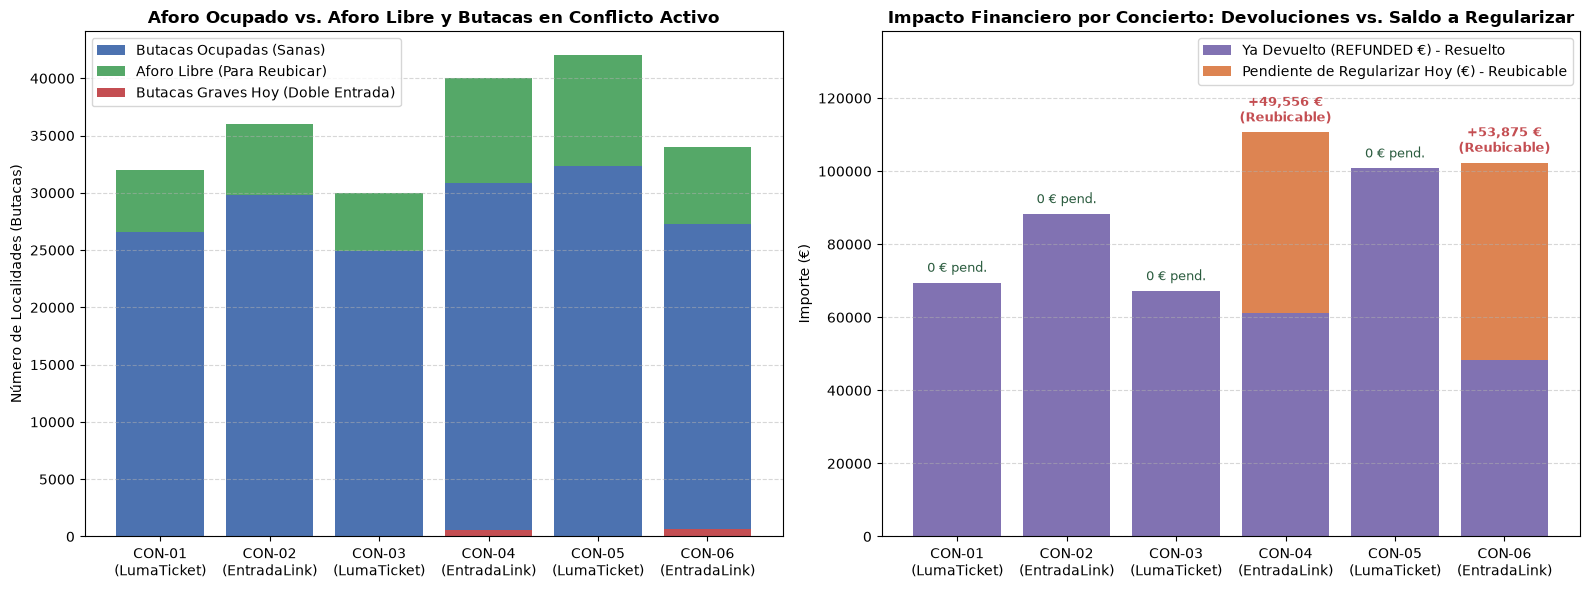

In [25]:
import matplotlib.pyplot as plt

df_plot_aforo = tabla_contexto_aforo(master)
df_plot_fin = tabla_gravedad_y_finanzas(master, ['concert_id', 'artist', 'ticketing_company_name'])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- GRÁFICO 1: Aforo Ocupado vs Aforo Libre vs Butacas Graves Hoy ---
x = np.arange(len(df_plot_aforo))
etiquetas = [f"{r['concert_id']}\n({r['ticketing_company_name']})" for _, r in df_plot_fin.iterrows()]

axes[0].bar(x, df_plot_aforo['Butacas Vendidas (Ocupadas)'], label='Butacas Ocupadas (Sanas)', color='#4C72B0')
axes[0].bar(x, df_plot_aforo['Aforo Libre (Asientos Vacíos)'],
            bottom=df_plot_aforo['Butacas Vendidas (Ocupadas)'], label='Aforo Libre (Para Reubicar)', color='#55A868')
axes[0].bar(x, df_plot_aforo['GRAVES Hoy: Butacas con 2 personas a la vez'],
            label='Butacas Graves Hoy (Doble Entrada)', color='#C44E52')

axes[0].set_title('Aforo Ocupado vs. Aforo Libre y Butacas en Conflicto Activo', fontsize=12, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(etiquetas)
axes[0].set_ylabel('Número de Localidades (Butacas)')
axes[0].legend()
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# --- GRÁFICO 2: Desglose Financiero en Incidencias (Devoluciones Hechas vs Regularización Pendiente) ---
devueltos = df_plot_fin['16. Devoluciones Ya Ejecutadas (REFUNDED €)']
pendientes = df_plot_fin['19. TOTAL IMPORTE PENDIENTE DE REGULARIZAR HOY (17 + 18) (€)']

axes[1].bar(x, devueltos, label='Ya Devuelto (REFUNDED €) - Resuelto', color='#8172B2')
axes[1].bar(x, pendientes, bottom=devueltos, label='Pendiente de Regularizar Hoy (€) - Reubicable', color='#DD8452')

for i, (d, p) in enumerate(zip(devueltos, pendientes)):
    if p > 0:
        axes[1].text(i, d + p + 3000, f'+{p:,.0f} €\n(Reubicable)', ha='center', fontsize=9, fontweight='bold', color='#C44E52')
    else:
        axes[1].text(i, d + 3000, '0 € pend.', ha='center', fontsize=9, color='#2b5c3f')

axes[1].set_title('Impacto Financiero por Concierto: Devoluciones vs. Saldo a Regularizar', fontsize=12, fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels(etiquetas)
axes[1].set_ylabel('Importe (€)')
axes[1].set_ylim(0, max(devueltos + pendientes) * 1.25)
axes[1].legend()
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# StageOps — Punto 5: Proponer una actuación

> *"05. Proponer una actuación. Prioricen tres medidas conectadas con las evidencias y expliquen cómo verificarían que evitan la repetición del problema."*

---

## 1. Control automático de las dos reglas

**¿Por qué hacemos este paso?** Antes de proponer medidas se prepara un control que se pueda repetir. Comprueba las dos reglas que se incumplen: entradas vigentes emitidas con aviso tardío y butacas con dos entradas vigentes. El mismo control sirve después para **verificar** que cada medida funciona. `def` define una función, un bloque de código reutilizable.

In [26]:
def p5_control(tickets, capturas, reservations, cierre):
    """Cuenta las entradas vigentes con aviso tardío y las butacas con dos entradas vigentes."""
    t = tickets.merge(capturas[["payment_id", "received_at"]], on="payment_id")
    t = t.merge(reservations[["reservation_id", "expires_at"]], on="reservation_id")
    tardias_vigentes = t[(t["received_at"] >= t["expires_at"]) & t["voided_at"].isna()]

    # Butacas con más de una entrada vigente (sin anular) al cierre
    vigentes = tickets[tickets["voided_at"].isna() | (tickets["voided_at"] > cierre)]
    por_butaca = vigentes.groupby(["concert_id", "seat_id"]).size()
    return {"entradas vigentes con aviso tardío": len(tardias_vigentes),
            "butacas con dos entradas vigentes": int((por_butaca > 1).sum())}

p5_control(p1_tickets, p1_capturas, p1_reservations, p1_snapshot)

{'entradas vigentes con aviso tardío': 2188,
 'butacas con dos entradas vigentes': 1195}

## 2. Medida 1 (urgente, antes de la próxima apertura): restaurar la validación en EntradaLink

**Qué.** Volver a la regla `CURRENT_OWNER_AND_NOT_EXPIRED` en el emisor de EntradaLink, revirtiendo CHG-004 o corrigiendo la 4.8.0. Al llegar el aviso de pago, el emisor debe comprobar que la reserva sigue vigente y que la butaca sigue siendo del comprador. Si no es así, devuelve el dinero sin emitir entrada.

**Evidencia.** Las 2.188 entradas incorrectas son de la versión 4.8.0. Con la regla original, LumaTicket resolvió bien 1.033 avisos tardíos y EntradaLink 448 antes del cambio.

**Cómo se verifica.**
- Antes de abrir ventas: se reenvían al emisor corregido los avisos tardíos de los 2.188 casos reales. El resultado debe ser 0 entradas y 2.188 devoluciones.
- Durante la próxima apertura: el control del paso 1, ejecutado cada pocos minutos, debe dar 0 entradas vigentes con aviso tardío.
- Ninguna entrada nueva puede llevar la versión 4.8.0 sin corregir.

## 3. Medida 2 (inmediata, con los clientes): regularizar las 2.188 entradas incorrectas

**Qué.** Hay que resolver cada entrada emitida con la reserva caducada antes de los conciertos (febrero y marzo de 2027) y avisar a cada comprador.
- **1.195 butacas con dos entradas.** Se mantiene la entrada del comprador que reservó correctamente. Al otro se le ofrece la **reubicación en el aforo libre**, con butacas de igual o mejor categoría y juntas si es un pedido de grupo, como propone el Punto 4. Si no la acepta, se le devuelve el importe.
- **993 entradas incorrectas sin choque.** La regla dice que había que devolver el dinero. Como la butaca está libre, dirección puede decidir mantenerlas: es una decisión comercial que hay que tomar de forma explícita.

**¿Por qué hacemos este paso en código?** Se genera la lista de trabajo con cada entrada, comprador, butaca e importe.

In [27]:
p5_lista = p1_indebidas[["ticket_id", "reservation_id", "order_id", "customer_id", "concert_id", "seat_id", "amount_eur"]].copy()
p5_lista["butaca_con_dos_entradas"] = p5_lista.set_index(["concert_id", "seat_id"]).index.isin(
    p1_dobles.set_index(["concert_id", "seat_id"]).index)

print("Entradas a regularizar:", len(p5_lista), "| compradores:", p5_lista["customer_id"].nunique(),
      "| importe:", p5_lista["amount_eur"].sum(), "€")
p5_lista.groupby(["concert_id", "butaca_con_dos_entradas"]).agg(
    entradas=("ticket_id", "size"), compradores=("customer_id", "nunique"), importe_eur=("amount_eur", "sum"))

Entradas a regularizar: 2188 | compradores: 2086 | importe: 187738.0 €


entradas  compradores  importe_eur
concert_id butaca_con_dos_entradas                                    
CON-04     False                         506          502    44,064.00
           True                          560          545    49,556.00
CON-06     False                         487          474    40,243.00
           True                          635          624    53,875.00

**Cómo se verifica.** Se simula la regularización (las entradas incorrectas dejan de estar vigentes) y se repite el mismo control: debe dar **0 y 0**. El importe no es una pérdida: se reubica (se mantiene el ingreso) o se devuelve.

In [28]:
# Simulación: las entradas incorrectas quedan anuladas en el cierre de los datos
p5_tickets_corregidos = p1_tickets.copy()
p5_corte = p1_snapshot - pd.Timedelta(seconds=1)
p5_tickets_corregidos.loc[p5_tickets_corregidos["ticket_id"].isin(p5_lista["ticket_id"]), "voided_at"] = p5_corte

print("Antes:  ", p5_control(p1_tickets, p1_capturas, p1_reservations, p1_snapshot))
print("Después:", p5_control(p5_tickets_corregidos, p1_capturas, p1_reservations, p1_snapshot))

Antes:   {'entradas vigentes con aviso tardío': 2188, 'butacas con dos entradas vigentes': 1195}
Después: {'entradas vigentes con aviso tardío': 0, 'butacas con dos entradas vigentes': 0}


## 4. Medida 3 (permanente): vigilancia automática y control de cambios en días de apertura

**Qué.**
- **Alerta automática.** El control del paso 1 se ejecuta durante cada venta. Si aparece una sola entrada con aviso tardío o una butaca con dos entradas, salta una alerta. Esta vez el fallo duró 8 horas el 16/10 sin que nadie lo detectara, y se repitió el 23/10.
- **Ningún cambio en el emisor (`ticket_issuer`) en día de apertura.** CHG-004 se instaló 20 minutos después de abrir la venta de CON-04. Todo cambio se prueba antes con avisos tardíos simulados.
- **Prueba de carga antes de cada apertura**, con el volumen real: 1.100 – 1.500 compras por minuto y avisos que llegan hasta 17,7 minutos tarde. Así se confirma que los avisos tardíos acaban en devolución.

**Cómo se verifica.** Se reproduce la alerta con los datos del expediente. Si salta en el primer minuto tras las 10:20Z del 16/10, la medida habría evitado el 23/10 entero.

In [29]:
# ¿Cuándo habría saltado la alerta? Primera entrada incorrecta de cada concierto (hora de España)
p1_indebidas.groupby("concert_id")["issued_at"].min().dt.tz_convert("Europe/Madrid").dt.strftime("%d/%m %H:%M:%S")

concert_id
CON-04    16/10 12:20:02
CON-06    23/10 12:12:48
Name: issued_at, dtype: str

---
## 📝 5. Conclusiones Redactadas del Punto 5 (Listas para el Informe)

| Prioridad | Medida | Evidencia | Cómo se verifica |
|---|---|---|---|
| **1** | Restaurar `CURRENT_OWNER_AND_NOT_EXPIRED` en el emisor de EntradaLink (revertir o corregir CHG-004) | 2.188 entradas incorrectas, todas de la 4.8.0; LumaTicket y EntradaLink antes del cambio resolvieron bien 1.481 avisos tardíos | Reenviar los 2.188 avisos tardíos al emisor corregido: 0 entradas y 2.188 devoluciones. En la próxima apertura, el control debe dar 0 |
| **2** | Regularizar las 2.188 entradas (187.738 €): reubicar o devolver las 1.195 dobles (103.431 €, la misma cifra del Punto 4); decisión de dirección sobre las 993 sin choque (84.307 €) | 1.195 butacas con dos entradas vigentes; 993 entradas que la regla no permitía | Repetir el control tras la regularización: 0 entradas vigentes con aviso tardío y 0 butacas con dos entradas |
| **3** | Alerta automática durante la venta, sin cambios en el emisor en días de apertura y con prueba de carga previa | El fallo solo aparece con volumen de apertura y pasó desapercibido del 16/10 al 23/10 | La alerta, aplicada a estos datos, salta el 16/10 a las 12:20, en el primer minuto |

**Orden.** Primero se corta el origen (medida 1): mientras siga la 4.8.0, cada apertura crea nuevos casos. Después se resuelve a los clientes afectados antes de los conciertos (medida 2). Por último se evita que un fallo parecido vuelva a pasar desapercibido (medida 3).